# Zehirli / Zehirsiz Böcek Sınıflandırması — Omurga Karşılaştırması

Bu notebook, iNaturalist'ten toplanan iki veri setini (*Zehirli Bocek Veri Toplama* ve *Zehirli Bocek Ek Veri*) birleştirip iki farklı yaklaşımı eğitir ve karşılaştırır:

| | Yaklaşım | Çıktı |
|---|---|---|
| **Model A** | Doğrudan ikili sınıflandırma | zehirli / zehirsiz |
| **Model B** | Hiyerarşik: önce 38 takson grubu, sonra gruptan zehir durumu | grup → zehirli / zehirsiz |

**Model:** ImageNet üzerinde önceden eğitilmiş **EfficientNet-B0** (transfer öğrenme), 224×224 giriş.

**Veri:** 38 gruptan her birinden 190 fotoğraf (toplam ~7.200) doğrudan iNaturalist'ten çekilip 224×224 olarak belleğe alınır; veri artırma (yatay çevirme, rastgele kırpma/yakınlaştırma, parlaklık ve kontrast) GPU üzerinde yapılır.

**Veri bölme:**
- Her gruptaki türlerin bir kısmı **hiç eğitime girmez** (*görülmemiş tür testi*): modelin daha önce hiç görmediği türlerde zehirliliği ne kadar genelleyebildiğini ölçer.
- Kalan veri gruplara göre katmanlı olarak %80 eğitim, %10 doğrulama, %10 test şeklinde bölünür.

**Dengesizlik:** Ağırlıklı örnekleme: her sınıf (zehirli/zehirsiz) %50, sınıf içinde her grup eşit ağırlıkla örneklenir (oversampling).

**Değerlendirme:** Accuracy, F1, precision, zehirliler için recall (kaçırılan zehirli böcek tehlikelidir), ROC-AUC, karışıklık matrisleri, gruplara göre doğruluk, benzer görünümlü çiftler analizi ve Grad-CAM.

## 1. Kütüphaneler ve ayarlar

In [1]:
import os, glob, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda"
EPOCH = 10
BATCH = 128
LR = 3e-4
IMG = 224
GRUP_BASINA = 190
CIKTI = "/kaggle/working"
print("GPU sayısı:", torch.cuda.device_count(), "| CPU:", os.cpu_count())

GPU sayısı: 2 | CPU: 4


## 2. Fotoğrafları iNaturalist'ten çekme (her gruptan 190, toplam ~7.200)

Önceki notebook'larda (*Zehirli Bocek Veri Toplama* ve *Ek Veri*) tanımlanan 38 grubun her birinden 190 fotoğraf doğrudan iNaturalist'ten çekilir: Research Grade gözlemler, CC0 / CC-BY / CC-BY-NC lisanslı fotoğraflar, tırtıl gruplarında yalnızca larva evresi. Fotoğraflar 224×224'e getirilip doğrudan belleğe alınır.

In [2]:
import io, requests

API = "https://api.inaturalist.org/v1"
LISANSLAR = ["cc0", "cc-by", "cc-by-nc"]
LARVA = {"term_id": 1, "term_value_id": 6}

GRUPLAR_TANIM = [
    # takson,          sınıf,      larva, hariç tutulan
    ("Vespidae", "zehirli", False, None), ("Apis mellifera", "zehirli", False, None),
    ("Bombus", "zehirli", False, None), ("Solenopsis", "zehirli", False, None),
    ("Pompilidae", "zehirli", False, None), ("Mutillidae", "zehirli", False, None),
    ("Meloidae", "zehirli", False, None), ("Paederus", "zehirli", False, None),
    ("Reduviidae", "zehirli", False, None), ("Thaumetopoea", "zehirli", True, None),
    ("Megalopygidae", "zehirli", True, None), ("Limacodidae", "zehirli", True, None),
    ("Pogonomyrmex", "zehirli", False, None), ("Hemileucinae", "zehirli", True, None),
    ("Lymantriinae", "zehirli", True, None),
    ("Syrphidae", "zehirsiz", False, None), ("Muscidae", "zehirsiz", False, None),
    ("Tipulidae", "zehirsiz", False, None), ("Pieridae", "zehirsiz", False, None),
    ("Lycaenidae", "zehirsiz", False, None), ("Odonata", "zehirsiz", False, None),
    ("Acrididae", "zehirsiz", False, None), ("Tettigoniidae", "zehirsiz", False, None),
    ("Mantodea", "zehirsiz", False, None), ("Cicadidae", "zehirsiz", False, None),
    ("Cerambycidae", "zehirsiz", False, None), ("Chrysopidae", "zehirsiz", False, None),
    ("Meliponini", "zehirsiz", False, None), ("Formicinae", "zehirsiz", False, None),
    ("Staphylinidae", "zehirsiz", False, "Paederus"), ("Notodontidae", "zehirsiz", True, "Thaumetopoeinae"),
    ("Saturniinae", "zehirsiz", True, None), ("Sphingidae", "zehirsiz", True, None),
    ("Tenthredinidae", "zehirsiz", False, None), ("Sesiidae", "zehirsiz", False, None),
    ("Pentatomidae", "zehirsiz", False, None), ("Coreidae", "zehirsiz", False, None),
    ("Chrysomelidae", "zehirsiz", False, None),
]

oturum = requests.Session()
oturum.headers["User-Agent"] = "zehirli-bocek-ders-projesi (Kaggle notebook)"

def api(yol, **params):
    for deneme in range(5):
        time.sleep(1.0)
        try:
            r = oturum.get(f"{API}/{yol}", params=params, timeout=60)
            if r.status_code == 200:
                return r.json()
        except requests.RequestException:
            pass
        time.sleep(5 * (deneme + 1))
    raise RuntimeError(f"API isteği başarısız: {yol}")

def takson_id(ad):
    return next(t["id"] for t in api("taxa", q=ad, is_active="true", per_page=30)["results"] if t["name"] == ad)

satirlar = []
t0 = time.time()
for ad, sinif, larva, haric in GRUPLAR_TANIM:
    p = dict(taxon_id=takson_id(ad), quality_grade="research", photos="true",
             photo_license=",".join(LISANSLAR), per_page=200, order_by="id", order="desc")
    if haric:
        p["without_taxon_id"] = takson_id(haric)
    if larva:
        p.update(LARVA)
    n, sayfa = 0, 1
    while n < GRUP_BASINA and sayfa <= 5:
        sonuc = api("observations", page=sayfa, **p)["results"]
        if not sonuc:
            break
        for o in sonuc:
            foto = next((f for f in o["photos"] if f.get("license_code") in LISANSLAR), None)
            if foto is None or n >= GRUP_BASINA:
                continue
            satirlar.append(dict(sinif=sinif, grup=ad.replace(" ", "_"), photo_id=foto["id"],
                                 takson=o["taxon"]["name"], lisans=foto["license_code"], atif=foto.get("attribution"),
                                 url=foto["url"].replace("/square.", "/medium.")))
            n += 1
        sayfa += 1
    print(f"{ad:16s} {sinif:9s} {n} fotoğraf", flush=True)

veri = pd.DataFrame(satirlar).drop_duplicates("photo_id").reset_index(drop=True)
print(f"Liste hazır: {len(veri)} fotoğraf ({(time.time() - t0) / 60:.1f} dk)")

Vespidae         zehirli   190 fotoğraf
Apis mellifera   zehirli   190 fotoğraf
Bombus           zehirli   190 fotoğraf
Solenopsis       zehirli   190 fotoğraf
Pompilidae       zehirli   190 fotoğraf
Mutillidae       zehirli   190 fotoğraf
Meloidae         zehirli   190 fotoğraf
Paederus         zehirli   190 fotoğraf
Reduviidae       zehirli   190 fotoğraf
Thaumetopoea     zehirli   190 fotoğraf
Megalopygidae    zehirli   190 fotoğraf
Limacodidae      zehirli   190 fotoğraf
Pogonomyrmex     zehirli   190 fotoğraf
Hemileucinae     zehirli   190 fotoğraf
Lymantriinae     zehirli   190 fotoğraf
Syrphidae        zehirsiz  190 fotoğraf
Muscidae         zehirsiz  190 fotoğraf
Tipulidae        zehirsiz  190 fotoğraf
Pieridae         zehirsiz  190 fotoğraf
Lycaenidae       zehirsiz  190 fotoğraf
Odonata          zehirsiz  190 fotoğraf
Acrididae        zehirsiz  190 fotoğraf
Tettigoniidae    zehirsiz  190 fotoğraf
Mantodea         zehirsiz  190 fotoğraf
Cicadidae        zehirsiz  190 fotoğraf


In [3]:
GORUNTU = np.zeros((len(veri), IMG, IMG, 3), dtype=np.uint8)
basarili = np.zeros(len(veri), dtype=bool)

def indir(i):
    for deneme in range(3):
        try:
            r = requests.get(veri.url.iat[i], timeout=30)
            if r.status_code == 200:
                img = Image.open(io.BytesIO(r.content)).convert("RGB")
                k = IMG / min(img.size)
                img = img.resize((max(IMG, round(img.width * k)), max(IMG, round(img.height * k))), Image.BILINEAR)
                sol, ust = (img.width - IMG) // 2, (img.height - IMG) // 2
                GORUNTU[i] = np.asarray(img.crop((sol, ust, sol + IMG, ust + IMG)))
                basarili[i] = True
                return
        except Exception:
            pass
        time.sleep(2)

t0 = time.time()
with ThreadPoolExecutor(16) as ex:
    for j, _ in enumerate(ex.map(indir, range(len(veri))), 1):
        if j % 2000 == 0:
            print(f"{j}/{len(veri)} indirildi ({(time.time() - t0) / 60:.1f} dk)", flush=True)

GORUNTU = GORUNTU[basarili]
veri = veri[basarili].reset_index(drop=True)
GORUNTU_T = torch.from_numpy(GORUNTU)
veri.drop(columns="url").to_csv(f"{CIKTI}/metadata.csv", index=False)

veri["idx"] = np.arange(len(veri))
veri["etiket"] = (veri.sinif == "zehirli").astype(int)
GRUPLAR = sorted(veri.grup.unique())
grup_idx = {g: i for i, g in enumerate(GRUPLAR)}
veri["grup_id"] = veri.grup.map(grup_idx)
grup_sinif = veri.groupby("grup").sinif.first()
ZEHIRLI_GRUP_IDS = [grup_idx[g] for g in GRUPLAR if grup_sinif[g] == "zehirli"]

print(f"İndirme bitti: {len(veri)} fotoğraf | {(time.time() - t0) / 60:.1f} dk | {GORUNTU.nbytes / 1e9:.2f} GB")
print(f"{len(GRUPLAR)} grup | {veri.takson.nunique()} takson |", veri.sinif.value_counts().to_dict())

2000/7220 indirildi (0.9 dk)
4000/7220 indirildi (1.8 dk)
6000/7220 indirildi (2.7 dk)
İndirme bitti: 7220 fotoğraf | 3.2 dk | 1.09 GB
38 grup | 1788 takson | {'zehirsiz': 4370, 'zehirli': 2850}


## 3. Eğitim / doğrulama / test ve görülmemiş tür bölmesi

In [4]:
rng = np.random.default_rng(SEED)

# Görülmemiş tür testi: her grupta (en az 10 farklı taksonu olan) grubun ~%10'u kadar fotoğrafı
# oluşturan bazı taksonlar tamamen ayrılır. Tek başına grubun %5'inden büyük taksonlar ayrılmaz.
gorulmemis = []
for g, d in veri.groupby("grup"):
    say = d.takson.value_counts()
    if len(say) < 10:
        continue
    taksonlar = list(say.index)
    rng.shuffle(taksonlar)
    hedef, toplam = 0.10 * len(d), 0
    for t in taksonlar:
        if toplam >= hedef:
            break
        if say[t] > 0.05 * len(d):
            continue
        gorulmemis.append(t)
        toplam += say[t]

veri["bolum"] = "egitim"
veri.loc[veri.takson.isin(gorulmemis), "bolum"] = "gorulmemis_tur"

# Kalan veri: her grup içinde %80 eğitim, %10 doğrulama, %10 test
for g, idx in veri[veri.bolum == "egitim"].groupby("grup").groups.items():
    idx = rng.permutation(np.array(idx))
    n = len(idx)
    veri.loc[idx[: int(0.1 * n)], "bolum"] = "dogrulama"
    veri.loc[idx[int(0.1 * n): int(0.2 * n)], "bolum"] = "test"

veri.to_csv(f"{CIKTI}/veri_bolmesi.csv", index=False)
bol = {b: veri[veri.bolum == b].reset_index(drop=True) for b in ["egitim", "dogrulama", "test", "gorulmemis_tur"]}
print("Görülmemiş takson sayısı:", len(gorulmemis))
pd.crosstab(veri.bolum, veri.sinif, margins=True)

Görülmemiş takson sayısı: 359


sinif,zehirli,zehirsiz,All
bolum,,,
dogrulama,253,384,637
egitim,2084,3125,5209
gorulmemis_tur,252,471,723
test,261,390,651
All,2850,4370,7220


## 4. Veri artırma (GPU üzerinde) ve örnekleme

In [5]:
ORT = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def batch_hazirla(idx, egitim):
    """Bellekteki fotoğraflardan bir batch oluşturur; eğitimde GPU üzerinde veri artırma uygular."""
    x = GORUNTU_T[torch.as_tensor(idx)].to(DEVICE).permute(0, 3, 1, 2).contiguous().float().div_(255)
    if egitim:
        cevir = torch.rand(len(x), device=DEVICE) < 0.5                 # yatay çevirme
        x[cevir] = x[cevir].flip(3)
        s = int(IMG * np.random.uniform(0.7, 1.0))                       # rastgele kırpma + yakınlaştırma
        i0, j0 = np.random.randint(0, IMG - s + 1, 2)
        x = F.interpolate(x[:, :, i0:i0 + s, j0:j0 + s], size=IMG, mode="bilinear", align_corners=False)
        parlaklik = 1 + (torch.rand(len(x), 1, 1, 1, device=DEVICE) - 0.5) * 0.4
        kontrast = 1 + (torch.rand(len(x), 1, 1, 1, device=DEVICE) - 0.5) * 0.4
        ort = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (((x - ort) * kontrast + ort) * parlaklik).clamp_(0, 1)     # renk tonu değiştirilmez: uyarı renkleri önemli
    return (x - ORT) / STD

tr = bol["egitim"]
TR_IDX, TR_E, TR_G = tr.idx.values, torch.tensor(tr.etiket.values), torch.tensor(tr.grup_id.values)

# Her sınıf %50, sınıf içinde her grup eşit olasılıkla örneklenir
grup_sayisi = tr.groupby("sinif").grup.nunique()
AGIRLIK = torch.tensor((1.0 / (tr.sinif.map(grup_sayisi) * tr.grup.map(tr.grup.value_counts()))).values)
ADIM = len(tr) // BATCH

def egitim_batchleri():
    secim = torch.multinomial(AGIRLIK, ADIM * BATCH, replacement=True).view(ADIM, BATCH)
    for s in secim:
        yield TR_IDX[s.numpy()], TR_E[s], TR_G[s]

def eval_batchleri(df, boyut=256):
    for i in range(0, len(df), boyut):
        yield df.idx.values[i:i + boyut]

print({b: len(d) for b, d in bol.items()}, "| epoch başına adım:", ADIM)

{'egitim': 5209, 'dogrulama': 637, 'test': 651, 'gorulmemis_tur': 723} | epoch başına adım: 40


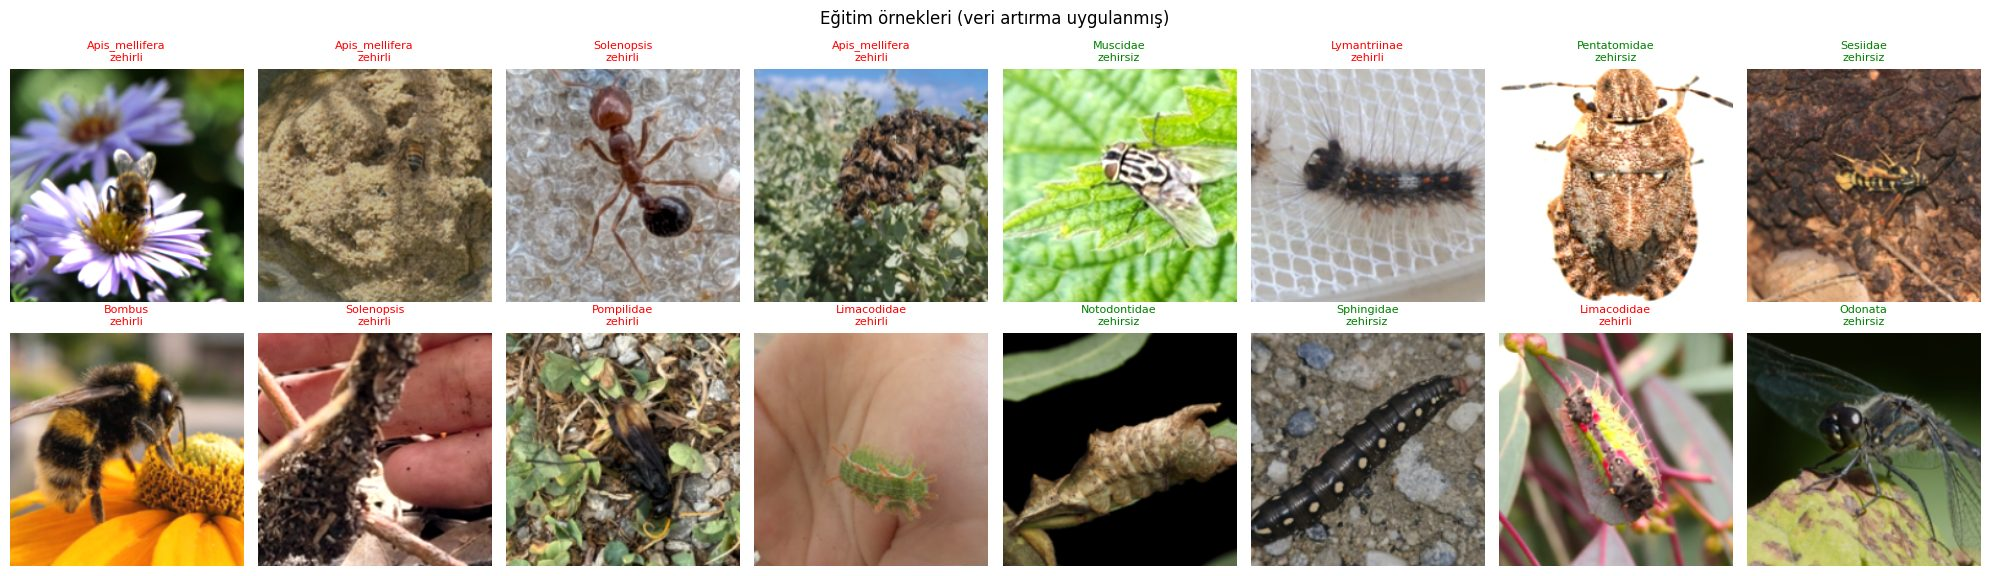

In [6]:
# Veri artırma örnekleri
idx, e, g = next(egitim_batchleri())
x = (batch_hazirla(idx[:16], True) * STD + ORT).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for ax, xi, ei, gi in zip(axes.flat, x, e[:16], g[:16]):
    ax.imshow(xi)
    ax.set_title(f"{GRUPLAR[gi]}\n{'zehirli' if ei else 'zehirsiz'}", fontsize=8, color="red" if ei else "green")
    ax.axis("off")
plt.suptitle("Eğitim örnekleri (veri artırma uygulanmış)"); plt.tight_layout(); plt.show()

## 5. Model karşılaştırması (omurga seçimi)

Hiyerarşik yaklaşım (Model B: önce 38 grup, sonra zehir durumu) üç farklı önceden eğitilmiş omurgayla, **aynı veri ve aynı bölmeyle** eğitilir:

| Omurga | Parametre | Not |
|---|---|---|
| EfficientNet-B0 | ~5 M | önceki çalışmalarda kullanılan model |
| EfficientNet-B3 | ~12 M | aynı ailenin daha büyük sürümü |
| ConvNeXt-Tiny | ~28 M | daha modern evrişimli mimari |

Değerlendirmede TTA (normal + aynalanmış görüntü) kullanılır.

In [7]:
OMURGALAR = {
    "EfficientNet-B0": (lambda: models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1), 3e-4),
    "EfficientNet-B3": (lambda: models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1), 2e-4),
    "ConvNeXt-Tiny":   (lambda: models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1), 1e-4),
}

def model_olustur(ad, n_cikis):
    m = OMURGALAR[ad][0]()
    if ad.startswith("EfficientNet"):
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_cikis)
    else:
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, n_cikis)
    return m

@torch.no_grad()
def tahmin_et(model, df):
    """TTA ile P(zehirli) ve grup olasılıkları."""
    model.eval()
    p_zehirli, p_grup = [], []
    for idx in eval_batchleri(df):
        with torch.autocast("cuda", dtype=torch.float16):
            x = batch_hazirla(idx, False)
            prob = (model(x).float().softmax(1) + model(x.flip(3)).float().softmax(1)) / 2
        p_grup.append(prob.cpu())
        p_zehirli.append(prob[:, ZEHIRLI_GRUP_IDS].sum(1).cpu())
    return torch.cat(p_zehirli).numpy(), torch.cat(p_grup).numpy()

def egit(ad):
    model = model_olustur(ad, len(GRUPLAR)).to(DEVICE)
    lr = OMURGALAR[ad][1]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=EPOCH * ADIM, pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda")
    kayip_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
    y_val = bol["dogrulama"].etiket.values
    t_bas = time.time()
    for ep in range(1, EPOCH + 1):
        model.train()
        t0, toplam, n = time.time(), 0.0, 0
        for idx, e, g in egitim_batchleri():
            x = batch_hazirla(idx, True)
            with torch.autocast("cuda", dtype=torch.float16):
                kayip = kayip_fn(model(x), g.to(DEVICE))
            opt.zero_grad(set_to_none=True)
            scaler.scale(kayip).backward()
            scaler.step(opt)
            scaler.update()
            sch.step()
            toplam += kayip.item() * len(x)
            n += len(x)
        p, _ = tahmin_et(model, bol["dogrulama"])
        print(f"[{ad}] epoch {ep}/{EPOCH} | kayıp={toplam / n:.4f} | val F1={f1_score(y_val, p > 0.5):.4f} | "
              f"{n / (time.time() - t0):.0f} foto/sn", flush=True)
    return model, (time.time() - t_bas) / 60

## 6. Üç omurgayı eğitme

In [8]:
def olc(y, p, esik=0.5):
    t = (p >= esik).astype(int)
    return dict(accuracy=accuracy_score(y, t), f1=f1_score(y, t), precision=precision_score(y, t, zero_division=0),
                recall_zehirli=recall_score(y, t), roc_auc=roc_auc_score(y, p))

sonuclar = []
for ad in OMURGALAR:
    torch.manual_seed(SEED); np.random.seed(SEED)
    model, sure = egit(ad)
    for b in ["test", "gorulmemis_tur"]:
        p, pg = tahmin_et(model, bol[b])
        sonuclar.append(dict(omurga=ad, bolum=b, egitim_dk=round(sure, 1),
                             grup_dogrulugu=(pg.argmax(1) == bol[b].grup_id.values).mean(),
                             **olc(bol[b].etiket.values, p)))
    torch.save(model.state_dict(), f"{CIKTI}/model_B_{ad}.pt")
    del model; torch.cuda.empty_cache()
    print(f"--- {ad} bitti ({sure:.1f} dk)", flush=True)

omurga_df = pd.DataFrame(sonuclar)
omurga_df.to_csv(f"{CIKTI}/omurga_karsilastirma.csv", index=False)
omurga_df.round(3)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 147MB/s]


[EfficientNet-B0] epoch 1/10 | kayıp=3.5655 | val F1=0.2614 | 150 foto/sn
[EfficientNet-B0] epoch 2/10 | kayıp=2.6151 | val F1=0.7725 | 375 foto/sn
[EfficientNet-B0] epoch 3/10 | kayıp=1.6658 | val F1=0.7766 | 368 foto/sn
[EfficientNet-B0] epoch 4/10 | kayıp=1.3385 | val F1=0.7715 | 357 foto/sn
[EfficientNet-B0] epoch 5/10 | kayıp=1.1829 | val F1=0.7942 | 345 foto/sn
[EfficientNet-B0] epoch 6/10 | kayıp=1.0748 | val F1=0.8098 | 324 foto/sn
[EfficientNet-B0] epoch 7/10 | kayıp=1.0049 | val F1=0.8140 | 306 foto/sn
[EfficientNet-B0] epoch 8/10 | kayıp=0.9736 | val F1=0.8122 | 314 foto/sn
[EfficientNet-B0] epoch 9/10 | kayıp=0.9429 | val F1=0.8033 | 328 foto/sn
[EfficientNet-B0] epoch 10/10 | kayıp=0.9456 | val F1=0.8098 | 330 foto/sn
--- EfficientNet-B0 bitti (2.8 dk)
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 166MB/s]


[EfficientNet-B3] epoch 1/10 | kayıp=3.6058 | val F1=0.0156 | 99 foto/sn
[EfficientNet-B3] epoch 2/10 | kayıp=3.0575 | val F1=0.6704 | 166 foto/sn
[EfficientNet-B3] epoch 3/10 | kayıp=1.9727 | val F1=0.7002 | 165 foto/sn
[EfficientNet-B3] epoch 4/10 | kayıp=1.4967 | val F1=0.7340 | 163 foto/sn
[EfficientNet-B3] epoch 5/10 | kayıp=1.3003 | val F1=0.7921 | 164 foto/sn
[EfficientNet-B3] epoch 6/10 | kayıp=1.1721 | val F1=0.8089 | 164 foto/sn
[EfficientNet-B3] epoch 7/10 | kayıp=1.0791 | val F1=0.7775 | 164 foto/sn
[EfficientNet-B3] epoch 8/10 | kayıp=1.0700 | val F1=0.7869 | 164 foto/sn
[EfficientNet-B3] epoch 9/10 | kayıp=1.0500 | val F1=0.8008 | 164 foto/sn
[EfficientNet-B3] epoch 10/10 | kayıp=1.0346 | val F1=0.8000 | 164 foto/sn
--- EfficientNet-B3 bitti (5.5 dk)
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 202MB/s] 


[ConvNeXt-Tiny] epoch 1/10 | kayıp=3.5493 | val F1=0.5232 | 96 foto/sn
[ConvNeXt-Tiny] epoch 2/10 | kayıp=2.4948 | val F1=0.7892 | 176 foto/sn
[ConvNeXt-Tiny] epoch 3/10 | kayıp=1.4903 | val F1=0.8306 | 177 foto/sn
[ConvNeXt-Tiny] epoch 4/10 | kayıp=1.1641 | val F1=0.8674 | 178 foto/sn
[ConvNeXt-Tiny] epoch 5/10 | kayıp=1.0295 | val F1=0.8861 | 177 foto/sn
[ConvNeXt-Tiny] epoch 6/10 | kayıp=0.9377 | val F1=0.8747 | 176 foto/sn
[ConvNeXt-Tiny] epoch 7/10 | kayıp=0.8925 | val F1=0.8843 | 176 foto/sn
[ConvNeXt-Tiny] epoch 8/10 | kayıp=0.8694 | val F1=0.8934 | 176 foto/sn
[ConvNeXt-Tiny] epoch 9/10 | kayıp=0.8566 | val F1=0.8893 | 176 foto/sn
[ConvNeXt-Tiny] epoch 10/10 | kayıp=0.8476 | val F1=0.8889 | 176 foto/sn
--- ConvNeXt-Tiny bitti (5.2 dk)


,omurga,bolum,egitim_dk,grup_dogrulugu,accuracy,f1,precision,recall_zehirli,roc_auc
0,EfficientNet-B0,test,2.8,0.739,0.883,0.850,0.874,0.828,0.953
1,EfficientNet-B0,gorulmemis_tur,2.8,0.578,0.808,0.723,0.727,0.718,0.891
2,EfficientNet-B3,test,5.5,0.631,0.829,0.787,0.788,0.785,0.916
3,EfficientNet-B3,gorulmemis_tur,5.5,0.521,0.790,0.705,0.689,0.722,0.876
4,ConvNeXt-Tiny,test,5.2,0.826,0.923,0.905,0.901,0.908,0.977
5,ConvNeXt-Tiny,gorulmemis_tur,5.2,0.732,0.869,0.813,0.808,0.817,0.943


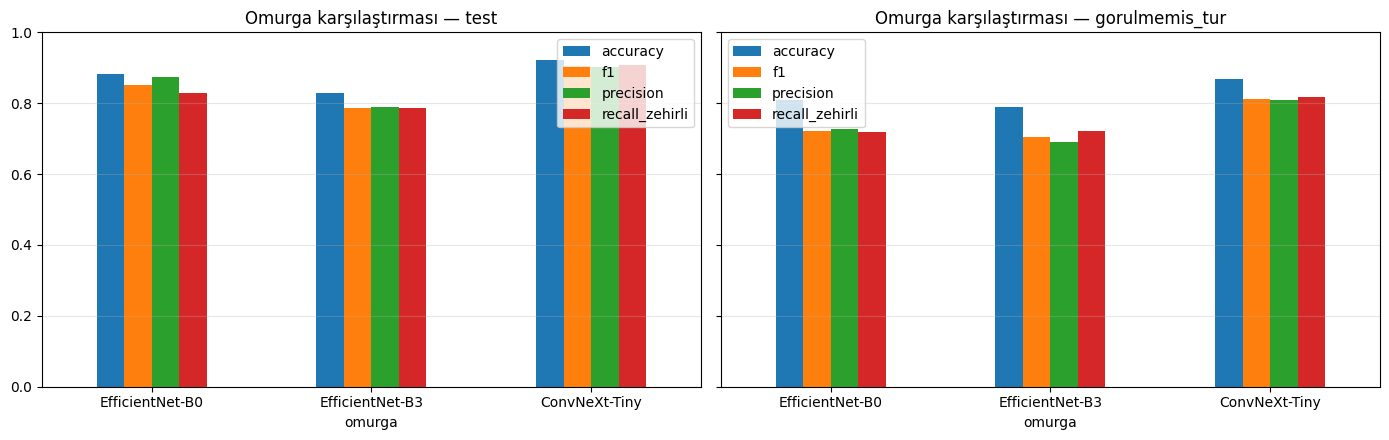

OMURGA KARŞILAŞTIRMASI (Model B, TTA)
         omurga          bolum  accuracy    f1  precision  recall_zehirli  roc_auc  egitim_dk
EfficientNet-B0           test     0.883 0.850      0.874           0.828    0.953        2.8
EfficientNet-B0 gorulmemis_tur     0.808 0.723      0.727           0.718    0.891        2.8
EfficientNet-B3           test     0.829 0.787      0.788           0.785    0.916        5.5
EfficientNet-B3 gorulmemis_tur     0.790 0.705      0.689           0.722    0.876        5.5
  ConvNeXt-Tiny           test     0.923 0.905      0.901           0.908    0.977        5.2
  ConvNeXt-Tiny gorulmemis_tur     0.869 0.813      0.808           0.817    0.943        5.2


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, b in zip(axes, ["test", "gorulmemis_tur"]):
    d = omurga_df[omurga_df.bolum == b].set_index("omurga")[["accuracy", "f1", "precision", "recall_zehirli"]]
    d.plot.bar(ax=ax, rot=0)
    ax.set_title(f"Omurga karşılaştırması — {b}"); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

print("=" * 80)
print("OMURGA KARŞILAŞTIRMASI (Model B, TTA)")
print("=" * 80)
print(omurga_df[["omurga", "bolum", "accuracy", "f1", "precision", "recall_zehirli", "roc_auc", "egitim_dk"]]
      .round(3).to_string(index=False))

---
# Klasik Görüntü İşleme

Bu bölümde, derin öğrenme kullanmadan **klasik görüntü işleme** teknikleri (OpenCV + NumPy) böcek fotoğrafları üzerinde adım adım uygulanır. Amaç, fotoğrafın bilgisayar için ne olduğunu, hangi bilgilerin (renk, kenar, doku, şekil) çıkarılabildiğini ve bunların zehirliliği ayırmaya yetip yetmediğini göstermektir.

| Bölüm | Teknik |
|---|---|
| 7 | Fotoğraf = sayı matrisi, piksel yakınlaştırma |
| 8 | Renk kanalları (RGB) |
| 9 | Gri tonlama ve histogram |
| 10 | Histogram eşitleme ve CLAHE |
| 11 | Gürültü ve filtreleme (ortalama, Gauss, medyan, bilateral) + PSNR |
| 12 | Evrişim çekirdekleri ve kenar bulma (Sobel, Laplace, Canny) |
| 13 | HSV renk uzayı ve uyarı rengi maskesi |
| 14 | Morfolojik işlemler |
| 15 | Segmentasyon: Otsu, GrabCut, kontur |
| 16 | 4 benzer çiftte sayısal renk / kenar analizi |

Kullanılan fotoğraflar: 4 benzer zehirli–zehirsiz çiftten (8 grup) her gruptan 25 fotoğraf, iNaturalist (Research Grade, CC0 / CC-BY / CC-BY-NC).

## 7. Örnek fotoğraflar ve "fotoğraf = sayı matrisi"

Vespidae        zehirli   25 fotoğraf


Syrphidae       zehirsiz  25 fotoğraf


Apis mellifera  zehirli   25 fotoğraf


Meliponini      zehirsiz  25 fotoğraf


Megalopygidae   zehirli   25 fotoğraf


Sphingidae      zehirsiz  25 fotoğraf


Reduviidae      zehirli   25 fotoğraf


Pentatomidae    zehirsiz  25 fotoğraf


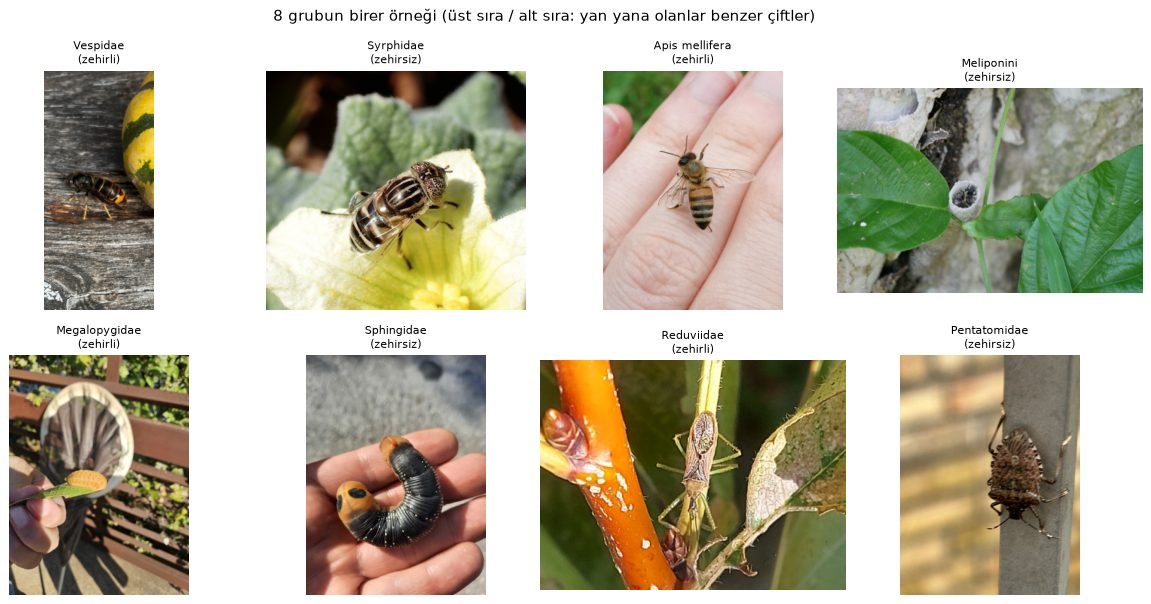

In [10]:
import io, time
import numpy as np
import pandas as pd
import cv2
import requests
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

plt.rcParams["figure.dpi"] = 90
np.random.seed(42)

def goster(resimler, basliklar, sutun=4, boyut=3.4, cmap="gray", baslik=None):
    """Resimleri ızgara halinde çizer (RGB ya da tek kanallı)."""
    satir = int(np.ceil(len(resimler) / sutun))
    fig, axes = plt.subplots(satir, sutun, figsize=(boyut * sutun, boyut * satir))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, r, b in zip(np.atleast_1d(axes).flat, resimler, basliklar):
        ax.imshow(r, cmap=None if r.ndim == 3 else cmap)
        ax.set_title(b, fontsize=9)
    if baslik:
        plt.suptitle(baslik, fontsize=12)
    plt.tight_layout(); plt.show()

API = "https://api.inaturalist.org/v1"
CIFT_GRUPLAR = [   # (takson, sınıf, sadece larva mı) — yan yana olanlar benzer çiftler
    ("Vespidae", "zehirli", False),       ("Syrphidae", "zehirsiz", False),
    ("Apis mellifera", "zehirli", False), ("Meliponini", "zehirsiz", False),
    ("Megalopygidae", "zehirli", True),   ("Sphingidae", "zehirsiz", True),
    ("Reduviidae", "zehirli", False),     ("Pentatomidae", "zehirsiz", False),
]

gi_oturum = requests.Session()
gi_oturum.headers["User-Agent"] = "zehirli-bocek-ders-projesi (goruntu isleme)"

def gi_api(yol, **params):
    for deneme in range(5):
        time.sleep(1.0)
        try:
            r = gi_oturum.get(f"{API}/{yol}", params=params, timeout=60)
            if r.status_code == 200:
                return r.json()
        except requests.RequestException:
            pass
        time.sleep(3 * (deneme + 1))
    raise RuntimeError(yol)

def foto_indir(url, en_buyuk=400):
    """Fotoğrafı indirir, OpenCV ile çözer (BGR → RGB) ve uzun kenarı 400 piksel yapar."""
    b = np.frombuffer(gi_oturum.get(url, timeout=30).content, np.uint8)
    rgb = cv2.cvtColor(cv2.imdecode(b, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    k = en_buyuk / max(rgb.shape[:2])
    return cv2.resize(rgb, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)

kayitlar = []
for ad, sinif, larva in CIFT_GRUPLAR:
    tid = next(t["id"] for t in gi_api("taxa", q=ad, per_page=30)["results"] if t["name"] == ad)
    p = dict(taxon_id=tid, quality_grade="research", photos="true", photo_license="cc0,cc-by,cc-by-nc",
             per_page=25, order_by="id", order="desc")
    if larva:
        p.update(term_id=1, term_value_id=6)
    for o in gi_api("observations", **p)["results"]:
        try:
            kayitlar.append(dict(grup=ad, sinif=sinif, resim=foto_indir(o["photos"][0]["url"].replace("/square.", "/medium."))))
        except Exception:
            pass
    print(f"{ad:15s} {sinif:9s} {sum(k['grup'] == ad for k in kayitlar)} fotoğraf")

gi_df = pd.DataFrame(kayitlar)
ornekler = gi_df.groupby("grup", sort=False).head(1).reset_index(drop=True)
ETIKET = [f"{g}\n({s})" for g, s in zip(ornekler.grup, ornekler.sinif)]
goster(list(ornekler.resim), ETIKET, baslik="8 grubun birer örneği (üst sıra / alt sıra: yan yana olanlar benzer çiftler)")

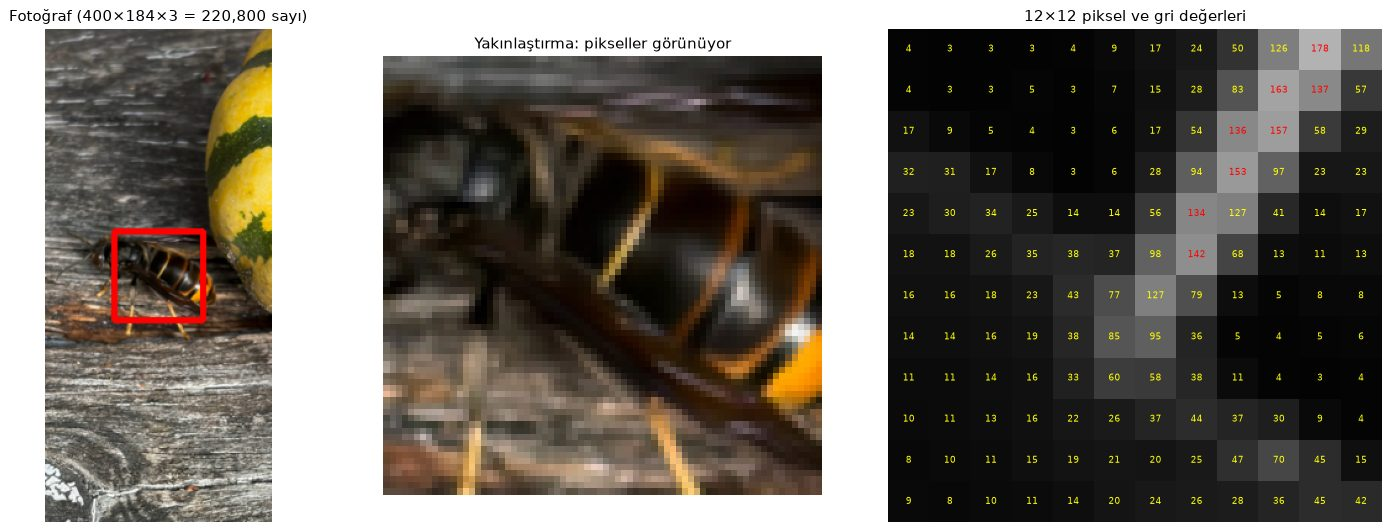

Boyut (yükseklik, genişlik, kanal): (400, 184, 3) | veri tipi: uint8


In [11]:
# Fotoğrafın içine yakınlaşma: her kare bir piksel, içindeki sayı o pikselin gri değeri (0 = siyah, 255 = beyaz)
foto = ornekler.resim[0].copy()
gri = cv2.cvtColor(foto, cv2.COLOR_RGB2GRAY)
h, w = gri.shape
y0, x0 = h // 2 - 6, w // 2 - 6
parca = gri[y0:y0 + 12, x0:x0 + 12]

fig, axes = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
cerceve = foto.copy()
cv2.rectangle(cerceve, (x0 - 30, y0 - 30), (x0 + 42, y0 + 42), (255, 0, 0), 3)
axes[0].imshow(cerceve); axes[0].set_title(f"Fotoğraf ({h}×{w}×3 = {h * w * 3:,} sayı)"); axes[0].axis("off")
axes[1].imshow(foto[y0 - 30:y0 + 42, x0 - 30:x0 + 42], interpolation="nearest"); axes[1].set_title("Yakınlaştırma: pikseller görünüyor"); axes[1].axis("off")
axes[2].imshow(parca, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for i in range(12):
    for j in range(12):
        axes[2].text(j, i, parca[i, j], ha="center", va="center", fontsize=7, color="red" if parca[i, j] > 127 else "yellow")
axes[2].set_title("12×12 piksel ve gri değerleri"); axes[2].axis("off")
plt.tight_layout(); plt.show()
print("Boyut (yükseklik, genişlik, kanal):", foto.shape, "| veri tipi:", foto.dtype)

## 8. Renk kanalları (RGB)

Her piksel **Kırmızı, Yeşil, Mavi** olmak üzere üç sayıdan (0–255) oluşur. Her kanal ayrı bir gri resim gibi gösterilebilir: parlak bölge = o renkten çok var. Sarı = kırmızı + yeşil olduğu için sarı bölgeler R ve G kanallarında parlak, B kanalında koyudur.

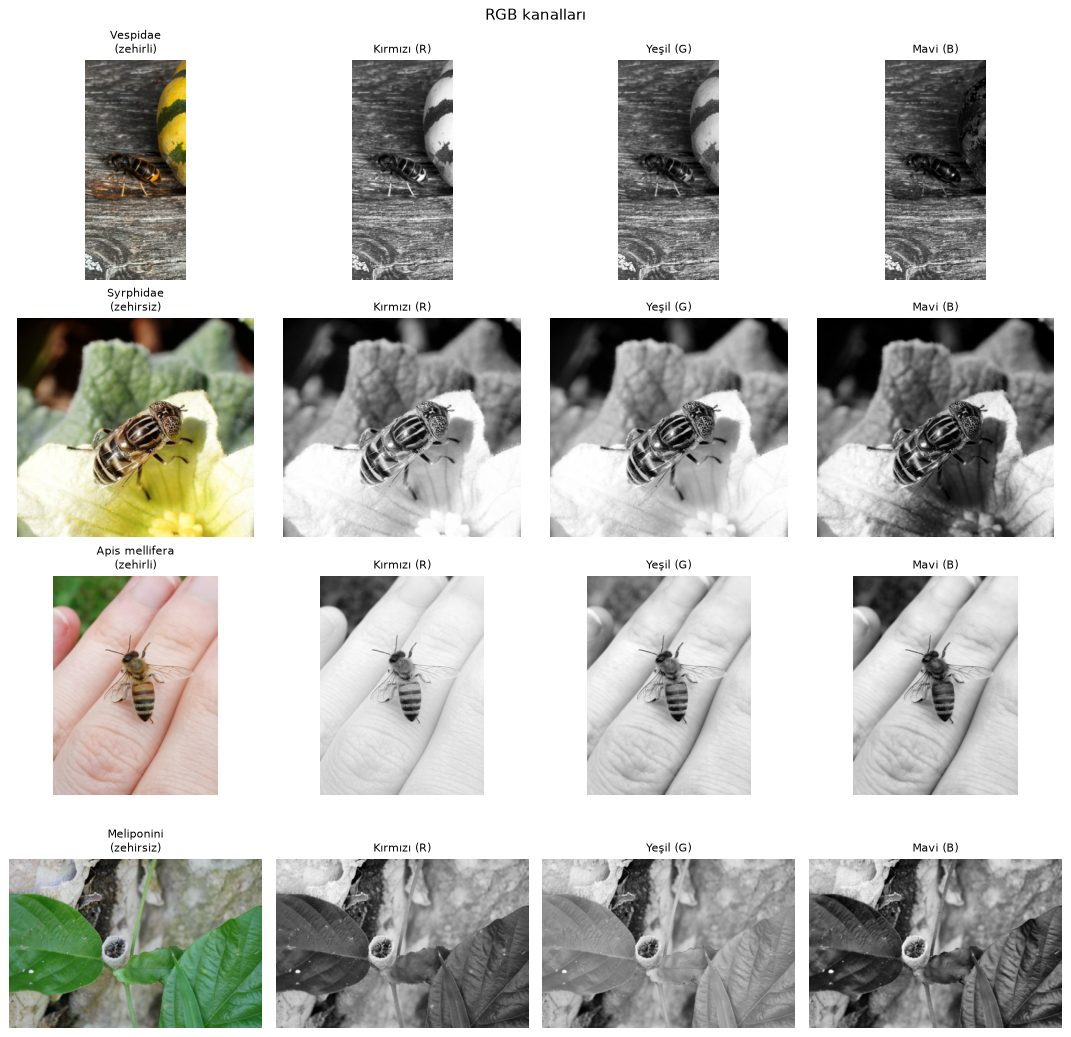

In [12]:
resimler, basliklar = [], []
for r, e in zip(ornekler.resim[:4], ETIKET[:4]):
    resimler += [r, r[:, :, 0], r[:, :, 1], r[:, :, 2]]
    basliklar += [e, "Kırmızı (R)", "Yeşil (G)", "Mavi (B)"]
goster(resimler, basliklar, sutun=4, boyut=3, baslik="RGB kanalları")

## 9. Gri tonlama ve histogram

`Gri = 0.299·R + 0.587·G + 0.114·B` (göz en çok yeşile duyarlıdır). **Histogram**, her parlaklık değerinden (0–255) kaç piksel olduğunu gösterir: solda yığılma = karanlık fotoğraf, sağda = aydınlık, dar = düşük kontrast.

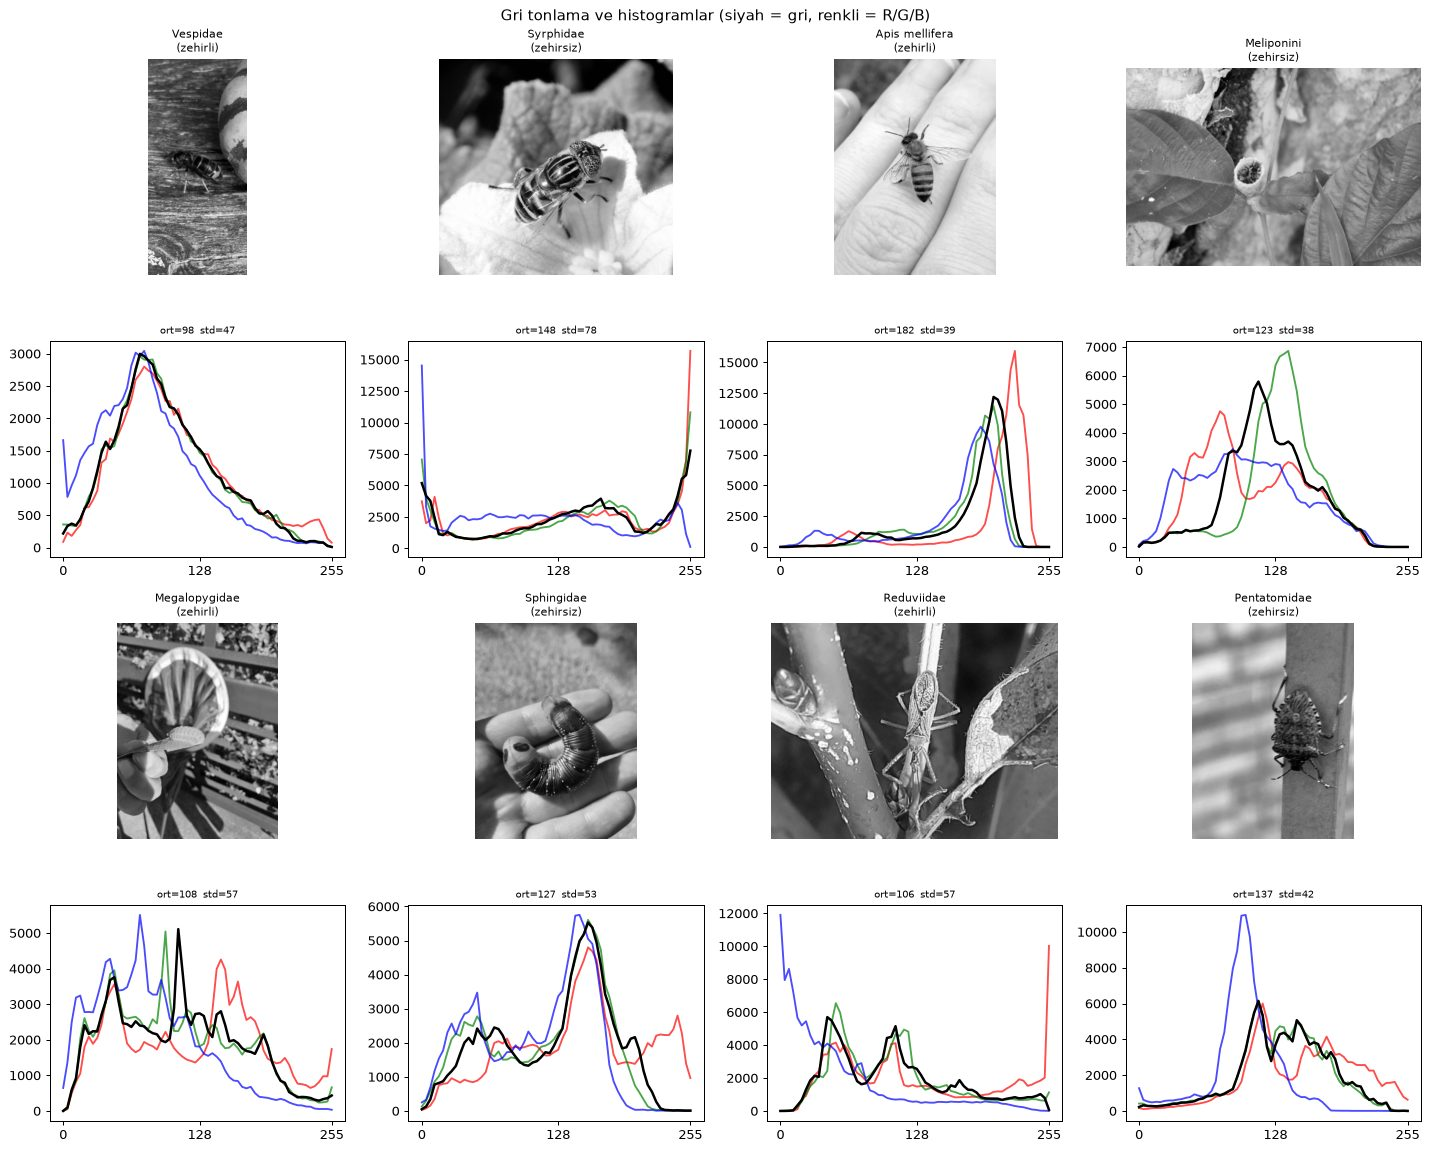

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for k, (r, e) in enumerate(zip(ornekler.resim, ETIKET)):
    g = cv2.cvtColor(r, cv2.COLOR_RGB2GRAY)
    a1, a2 = axes[(k // 4) * 2, k % 4], axes[(k // 4) * 2 + 1, k % 4]
    a1.imshow(g, cmap="gray"); a1.set_title(e, fontsize=9); a1.axis("off")
    for i, renk in enumerate(["red", "green", "blue"]):
        a2.plot(cv2.calcHist([r], [i], None, [64], [0, 256]), color=renk, alpha=0.7)
    a2.plot(cv2.calcHist([g], [0], None, [64], [0, 256]), color="black", lw=2)
    a2.set_title(f"ort={g.mean():.0f}  std={g.std():.0f}", fontsize=8); a2.set_xticks([0, 32, 63]); a2.set_xticklabels([0, 128, 255])
plt.suptitle("Gri tonlama ve histogramlar (siyah = gri, renkli = R/G/B)", fontsize=12)
plt.tight_layout(); plt.show()

## 10. Histogram eşitleme ve CLAHE

Karanlık / düşük kontrastlı fotoğrafta pikseller dar bir aralığa sıkışır. **Histogram eşitleme** bu değerleri 0–255'e yayar. **CLAHE** aynı işlemi fotoğrafı 8×8 karelere bölerek yerel olarak yapar ve gürültüyü aşırı büyütmez. Renkli fotoğrafta CLAHE yalnızca **parlaklık (L) kanalına** (LAB renk uzayı) uygulanır, böylece renkler bozulmaz.

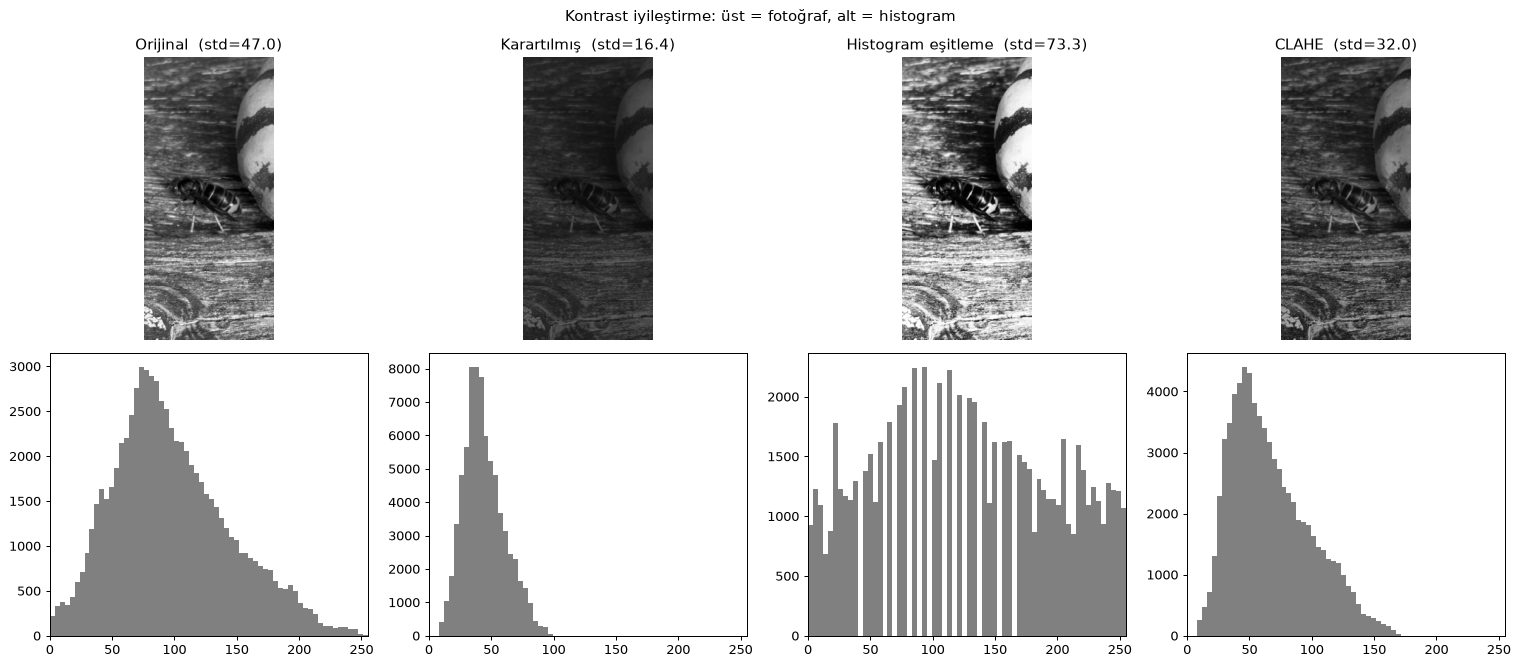

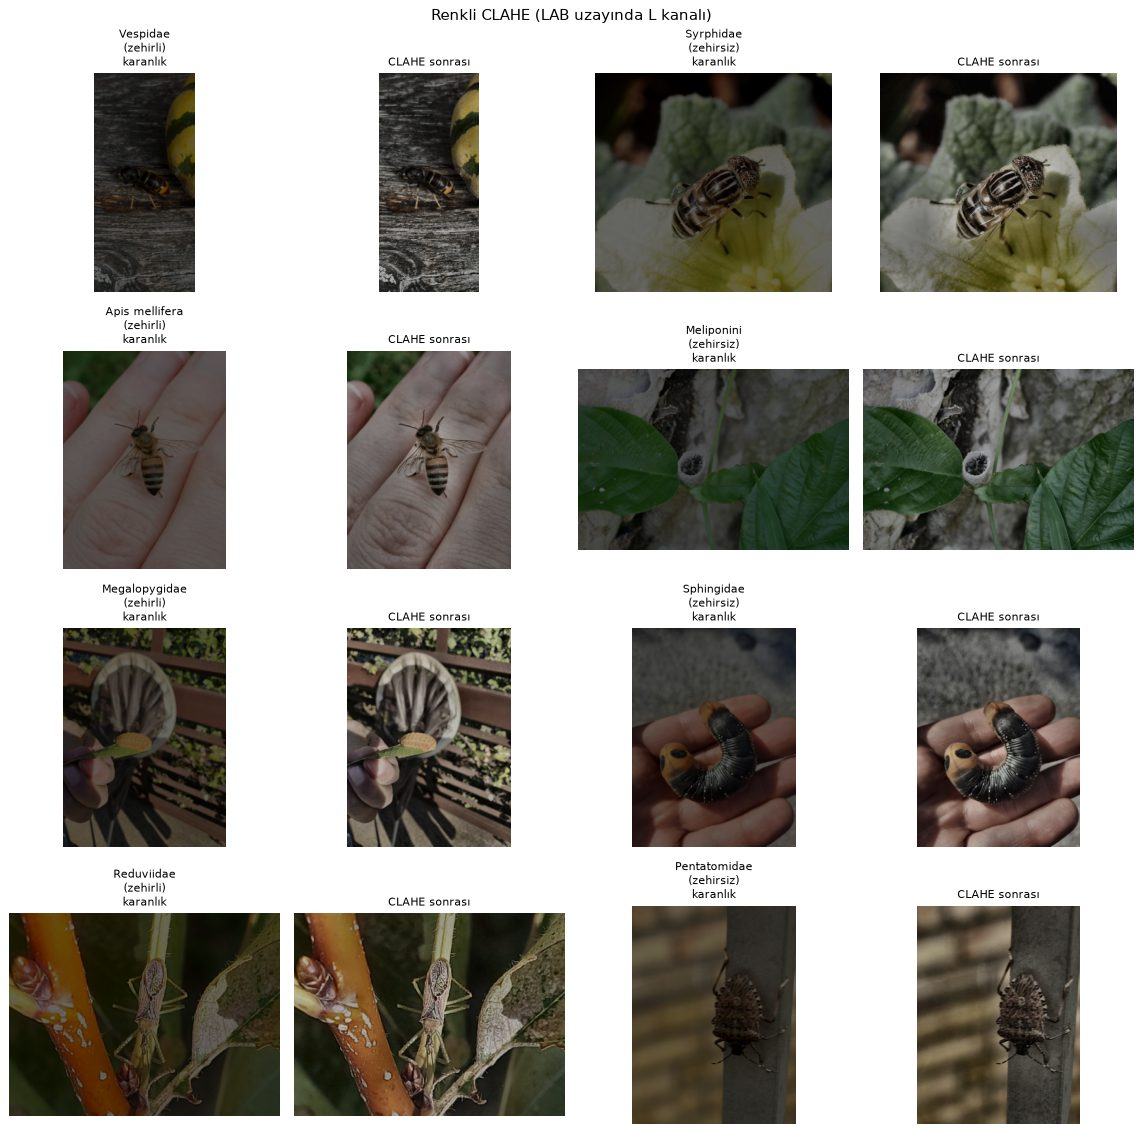

In [14]:
karanlik = (gri.astype(np.float32) * 0.35 + 10).astype(np.uint8)       # yapay olarak karartılmış
esit = cv2.equalizeHist(karanlik)
clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe = clahe_op.apply(karanlik)

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for j, (r, b) in enumerate([(gri, "Orijinal"), (karanlik, "Karartılmış"), (esit, "Histogram eşitleme"), (clahe, "CLAHE")]):
    axes[0, j].imshow(r, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(f"{b}  (std={r.std():.1f})"); axes[0, j].axis("off")
    axes[1, j].hist(r.ravel(), bins=64, range=(0, 255), color="gray"); axes[1, j].set_xlim(0, 255)
plt.suptitle("Kontrast iyileştirme: üst = fotoğraf, alt = histogram", fontsize=12)
plt.tight_layout(); plt.show()

def renkli_clahe(rgb, karart=1.0):
    lab = cv2.cvtColor((rgb * karart).astype(np.uint8), cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = clahe_op.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

resimler, basliklar = [], []
for r, e in zip(ornekler.resim, ETIKET):
    resimler += [(r * 0.4).astype(np.uint8), renkli_clahe(r, 0.4)]
    basliklar += [f"{e}\nkaranlık", "CLAHE sonrası"]
goster(resimler, basliklar, sutun=4, boyut=3.2, baslik="Renkli CLAHE (LAB uzayında L kanalı)")

## 11. Gürültü ve filtreleme

Fotoğrafa iki tür yapay gürültü eklenir ve filtreler denenir. Başarı **PSNR** (tepe sinyal-gürültü oranı, dB) ile ölçülür: orijinale ne kadar yakınsa o kadar yüksek.

| Filtre | Çalışma şekli |
|---|---|
| Ortalama 5×5 | penceredeki piksellerin ortalaması |
| Gauss 5×5 | merkeze yakın piksellere daha çok ağırlık veren ortalama |
| Medyan 3 / 5 | penceredeki değerlerin ortancası (aykırı noktalara dayanıklı) |
| Bilateral | hem uzaklığa hem renk benzerliğine göre ağırlık (kenarları korur) |

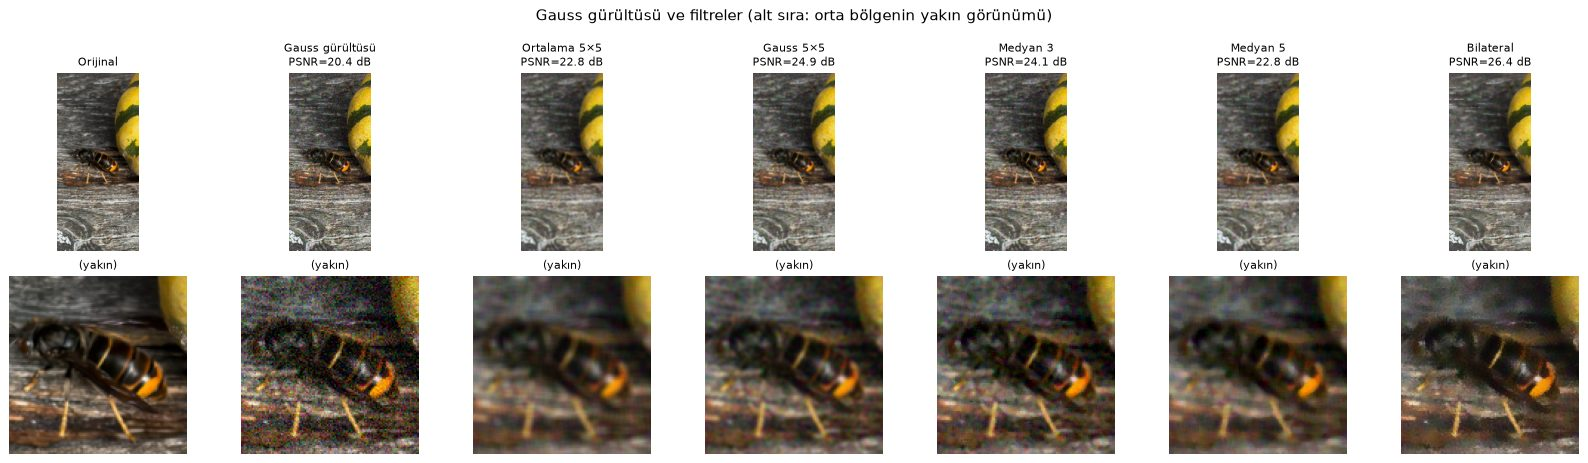

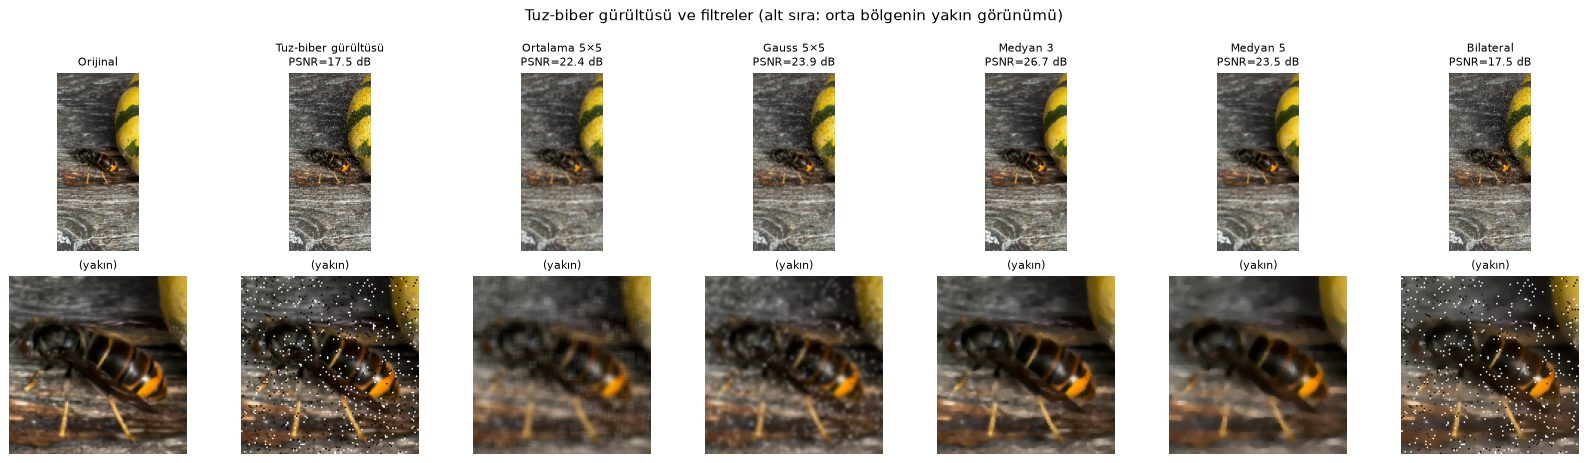

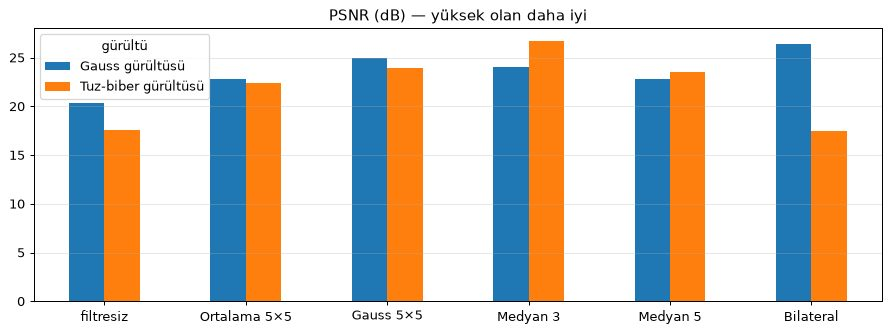

,filtresiz,Ortalama 5×5,Gauss 5×5,Medyan 3,Medyan 5,Bilateral
gürültü,,,,,,
Gauss gürültüsü,20.37,22.76,24.94,24.06,22.77,26.41
Tuz-biber gürültüsü,17.54,22.35,23.93,26.71,23.47,17.51


In [15]:
gauss_gurultu = np.clip(foto + np.random.normal(0, 25, foto.shape), 0, 255).astype(np.uint8)
tuz_biber = foto.copy()
m = np.random.rand(*foto.shape[:2])
tuz_biber[m < 0.03] = 0
tuz_biber[m > 0.97] = 255

def filtrele(x):
    return {"Ortalama 5×5": cv2.blur(x, (5, 5)), "Gauss 5×5": cv2.GaussianBlur(x, (5, 5), 0),
            "Medyan 3": cv2.medianBlur(x, 3), "Medyan 5": cv2.medianBlur(x, 5),
            "Bilateral": cv2.bilateralFilter(x, 9, 75, 75)}

yy, xx = foto.shape[0] // 2 - 60, foto.shape[1] // 2 - 60      # yakınlaştırılmış bölge (120×120)
satir = []
for g_ad, g in [("Gauss gürültüsü", gauss_gurultu), ("Tuz-biber gürültüsü", tuz_biber)]:
    sonuc = filtrele(g)
    hepsi = [("Orijinal", foto), (g_ad, g)] + list(sonuc.items())
    goster([v for _, v in hepsi] + [v[yy:yy + 120, xx:xx + 120] for _, v in hepsi],
           [f"{k}\nPSNR={cv2.PSNR(foto, v):.1f} dB" if k != "Orijinal" else k for k, v in hepsi] + ["(yakın)"] * len(hepsi),
           sutun=7, boyut=2.6, baslik=f"{g_ad} ve filtreler (alt sıra: orta bölgenin yakın görünümü)")
    satir.append({"gürültü": g_ad, "filtresiz": cv2.PSNR(foto, g), **{k: cv2.PSNR(foto, v) for k, v in sonuc.items()}})

psnr_df = pd.DataFrame(satir).set_index("gürültü").round(2)
psnr_df.T.plot.bar(figsize=(10, 3.8), rot=0, title="PSNR (dB) — yüksek olan daha iyi"); plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()
psnr_df

## 12. Evrişim (convolution) ve kenar bulma

**Evrişim:** Küçük bir sayı matrisi (çekirdek / filtre) resmin üzerinde kaydırılır; her konumda altındaki piksellerle çarpılıp toplanır. Çekirdeğin sayıları değişince sonuç tamamen değişir: bulanıklaştırma, keskinleştirme, kenar bulma... **CNN'lerin temel işlemi de budur**: CNN bu sayıları eğitim sırasında kendisi öğrenir, burada biz elle veriyoruz.

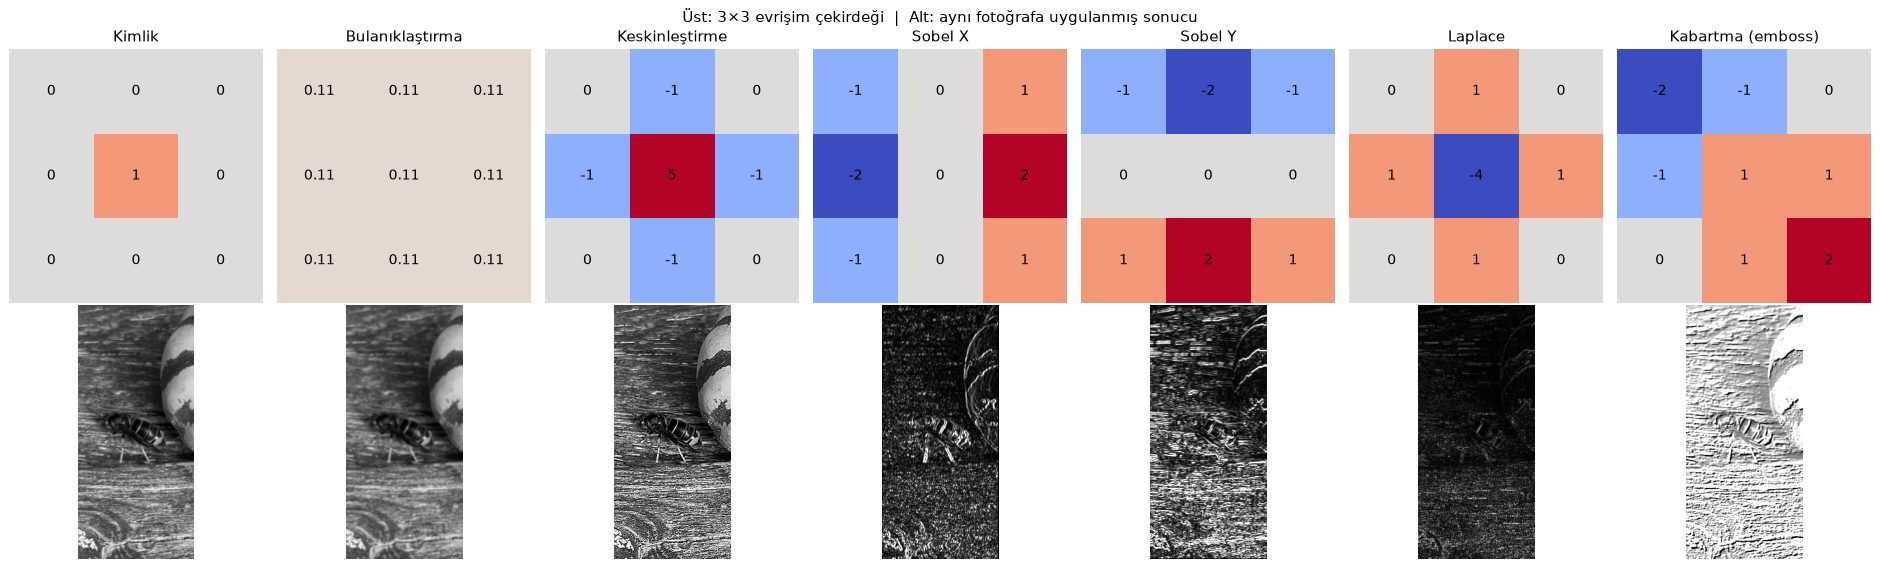

In [16]:
CEKIRDEKLER = {
    "Kimlik":            np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    "Bulanıklaştırma":   np.ones((3, 3)) / 9,
    "Keskinleştirme":    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Sobel X":           np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Sobel Y":           np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Laplace":           np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "Kabartma (emboss)": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]),
}
fig, axes = plt.subplots(2, len(CEKIRDEKLER), figsize=(3 * len(CEKIRDEKLER), 6.4))
for j, (ad, c) in enumerate(CEKIRDEKLER.items()):
    c = c.astype(np.float32)
    axes[0, j].imshow(c, cmap="coolwarm", vmin=-2, vmax=2)
    for (i, k), v in np.ndenumerate(c):
        axes[0, j].text(k, i, f"{v:.2g}", ha="center", va="center", fontsize=11)
    axes[0, j].set_title(ad); axes[0, j].axis("off")
    sonuc = cv2.filter2D(gri.astype(np.float32), -1, c)
    if ad in ("Sobel X", "Sobel Y", "Laplace"):
        sonuc = np.abs(sonuc)
    elif ad == "Kabartma (emboss)":
        sonuc = sonuc + 128
    axes[1, j].imshow(np.clip(sonuc, 0, 255), cmap="gray", vmin=0, vmax=255); axes[1, j].axis("off")
plt.suptitle("Üst: 3×3 evrişim çekirdeği  |  Alt: aynı fotoğrafa uygulanmış sonucu", fontsize=12)
plt.tight_layout(); plt.show()

Elle yazılan Sobel çekirdeği ile cv2.Sobel aynı sonucu veriyor mu? True


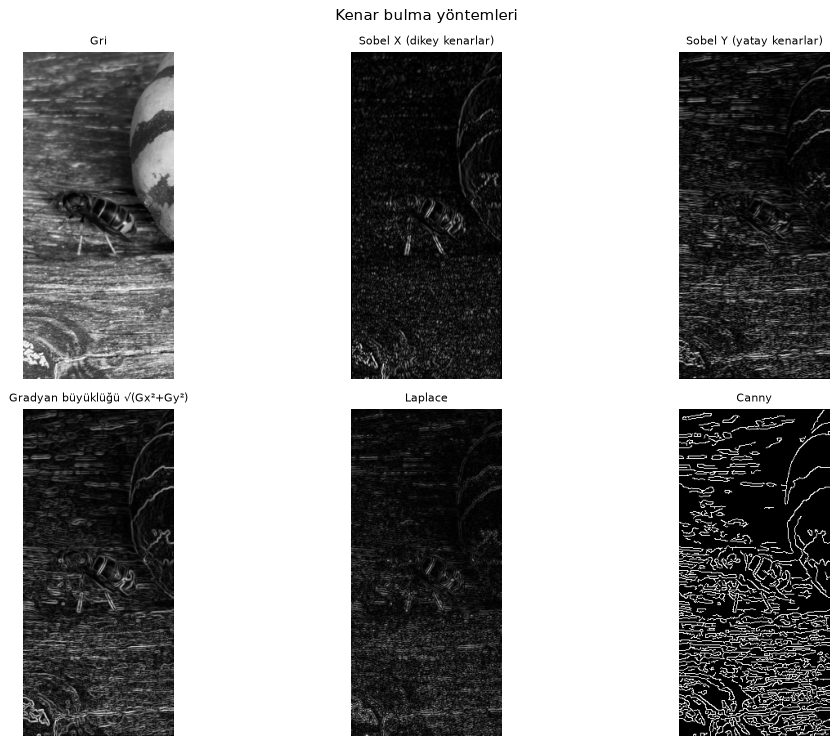

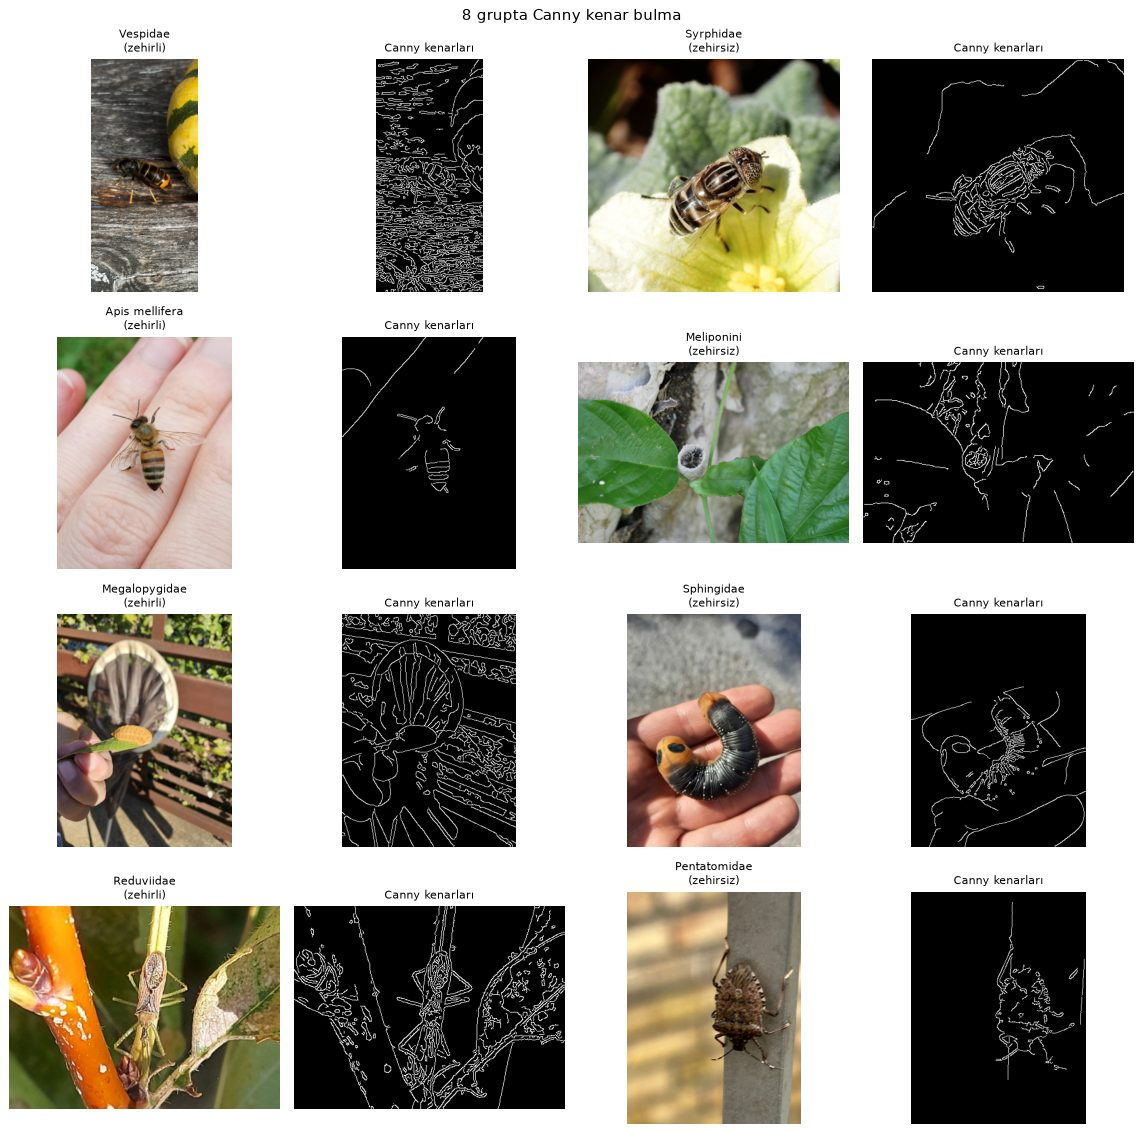

In [17]:
gx = cv2.Sobel(gri, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gri, cv2.CV_32F, 0, 1, ksize=3)
elle = cv2.filter2D(gri.astype(np.float32), -1, CEKIRDEKLER["Sobel X"].astype(np.float32))
print("Elle yazılan Sobel çekirdeği ile cv2.Sobel aynı sonucu veriyor mu?", np.allclose(elle, gx, atol=1e-3))

def canny(g):
    med = np.median(g)
    return cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), int(max(0, 0.66 * med)), int(min(255, 1.33 * med)))

goster([gri, np.abs(gx), np.abs(gy), cv2.magnitude(gx, gy),
        np.abs(cv2.Laplacian(cv2.GaussianBlur(gri, (3, 3), 0), cv2.CV_32F)), canny(gri)],
       ["Gri", "Sobel X (dikey kenarlar)", "Sobel Y (yatay kenarlar)", "Gradyan büyüklüğü √(Gx²+Gy²)", "Laplace", "Canny"],
       sutun=3, boyut=4.2, baslik="Kenar bulma yöntemleri")

resimler, basliklar = [], []
for r, e in zip(ornekler.resim, ETIKET):
    resimler += [r, canny(cv2.cvtColor(r, cv2.COLOR_RGB2GRAY))]
    basliklar += [e, "Canny kenarları"]
goster(resimler, basliklar, sutun=4, boyut=3.2, baslik="8 grupta Canny kenar bulma")

## 13. HSV renk uzayı ve uyarı rengi maskesi

RGB'de "sarı" üç kanala dağılmıştır. **HSV** rengi üç anlamlı parçaya ayırır: **H** (renk tonu, 0–179), **S** (doygunluk), **V** (parlaklık). Böylece bir rengi tek bir H aralığıyla seçmek kolaylaşır. Zehirli böceklerde sık görülen **uyarı renkleri** (aposematizm) maskelenir:
- **Sarı / turuncu:** H 10–35, S > 100, V > 100
- **Kırmızı:** H < 10 veya H > 165, S > 100, V > 80
- **Siyah:** V < 60

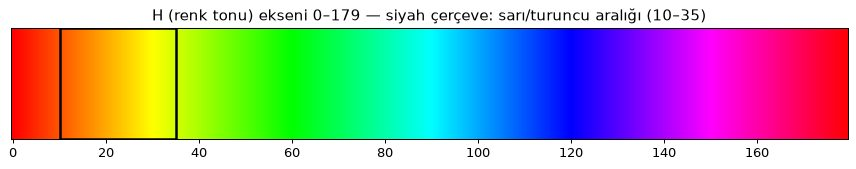

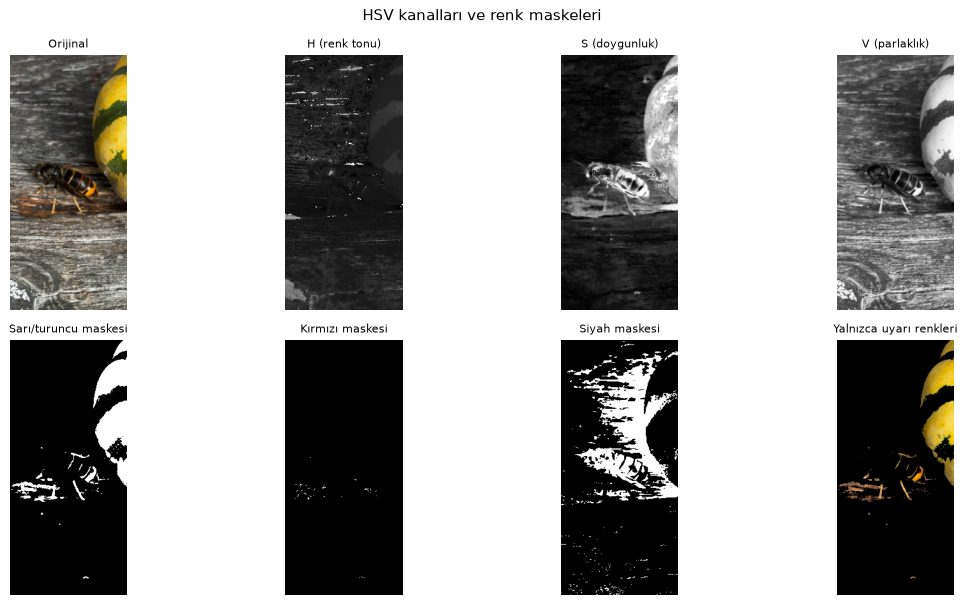

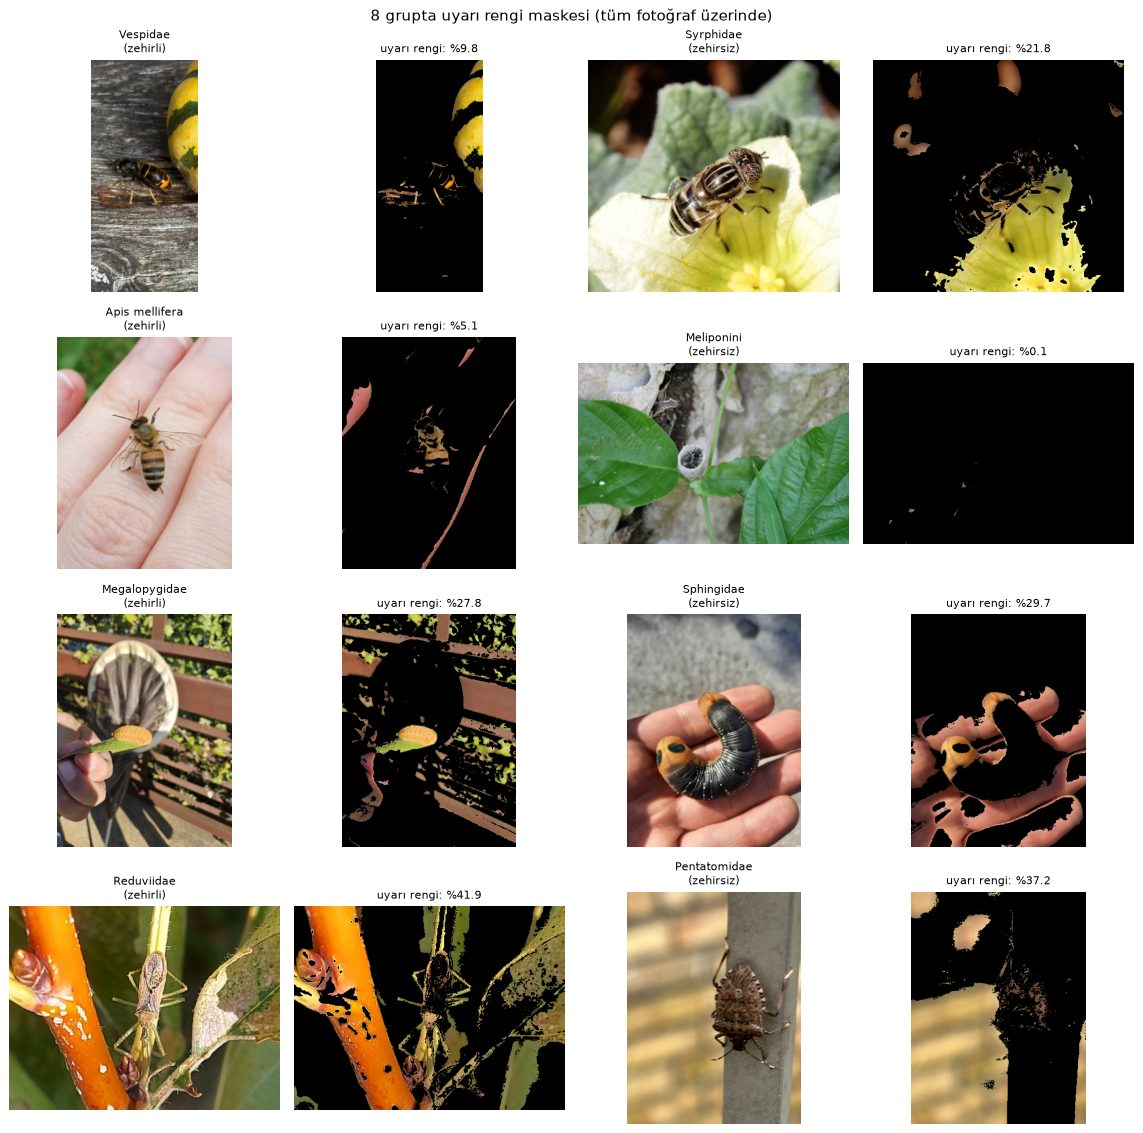

In [18]:
def renk_maskeleri(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    sari = cv2.inRange(hsv, (10, 100, 100), (35, 255, 255))
    kirmizi = cv2.inRange(hsv, (0, 100, 80), (10, 255, 255)) | cv2.inRange(hsv, (165, 100, 80), (179, 255, 255))
    siyah = cv2.inRange(hsv, (0, 0, 0), (179, 255, 60))
    return hsv, sari, kirmizi, siyah

# HSV renk tonu çemberi
ton = np.zeros((40, 180, 3), np.uint8); ton[:, :, 0] = np.arange(180); ton[:, :, 1:] = 255
plt.figure(figsize=(12, 1.6)); plt.imshow(cv2.cvtColor(ton, cv2.COLOR_HSV2RGB), aspect="auto")
plt.axvspan(10, 35, color="none", ec="black", lw=2); plt.title("H (renk tonu) ekseni 0–179 — siyah çerçeve: sarı/turuncu aralığı (10–35)")
plt.yticks([]); plt.show()

hsv, sari, kirmizi, siyah = renk_maskeleri(foto)
goster([foto, hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2], sari, kirmizi, siyah, cv2.bitwise_and(foto, foto, mask=sari | kirmizi)],
       ["Orijinal", "H (renk tonu)", "S (doygunluk)", "V (parlaklık)", "Sarı/turuncu maskesi", "Kırmızı maskesi", "Siyah maskesi", "Yalnızca uyarı renkleri"],
       baslik="HSV kanalları ve renk maskeleri")

resimler, basliklar = [], []
for r, e in zip(ornekler.resim, ETIKET):
    _, s, k, _ = renk_maskeleri(r)
    resimler += [r, cv2.bitwise_and(r, r, mask=s | k)]
    basliklar += [e, f"uyarı rengi: %{100 * ((s | k) > 0).mean():.1f}"]
goster(resimler, basliklar, sutun=4, boyut=3.2, baslik="8 grupta uyarı rengi maskesi (tüm fotoğraf üzerinde)")

## 14. Morfolojik işlemler

İkili (siyah-beyaz) maskelerdeki gürültüyü temizlemek için 5×5 elips şeklinde bir **yapı elemanı** kullanılır:
- **Aşındırma (erosion):** beyaz bölgeleri küçültür, küçük noktaları siler
- **Genişletme (dilation):** beyaz bölgeleri büyütür, boşlukları doldurur
- **Açma = aşındırma → genişletme:** küçük gürültü noktalarını temizler
- **Kapama = genişletme → aşındırma:** nesne içindeki küçük delikleri kapatır

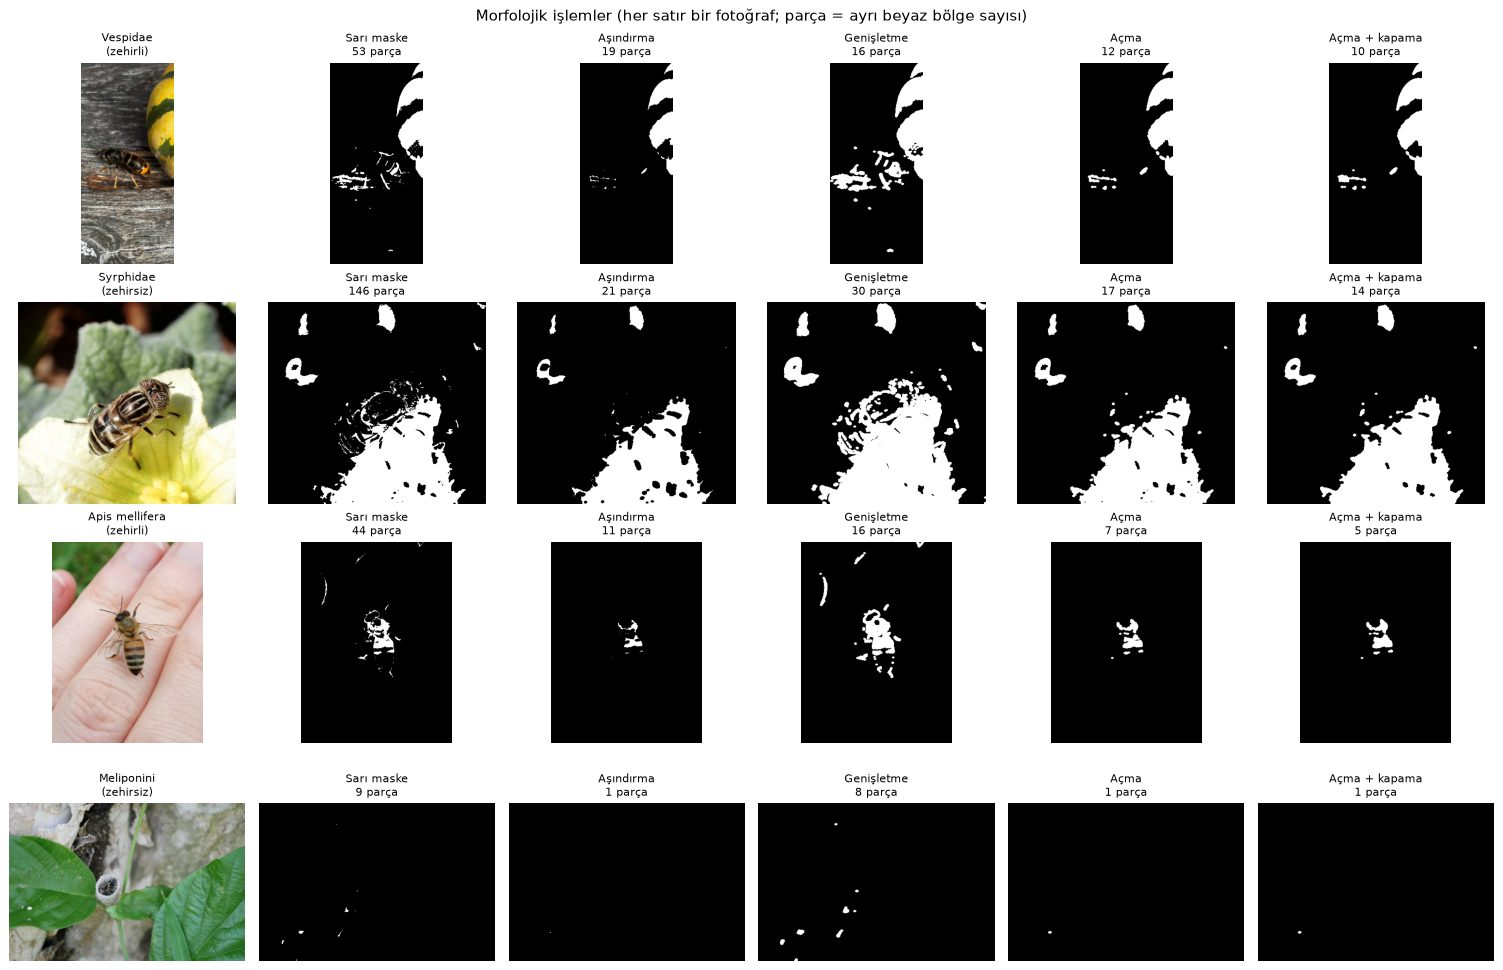

In [19]:
ye = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def parca_sayisi(m):
    return cv2.connectedComponents(m)[0] - 1

resimler, basliklar = [], []
for r, e in list(zip(ornekler.resim, ETIKET))[:4]:
    s = renk_maskeleri(r)[1]
    acma = cv2.morphologyEx(s, cv2.MORPH_OPEN, ye)
    adimlar = [("Sarı maske", s), ("Aşındırma", cv2.erode(s, ye)), ("Genişletme", cv2.dilate(s, ye)),
               ("Açma", acma), ("Açma + kapama", cv2.morphologyEx(acma, cv2.MORPH_CLOSE, ye))]
    resimler += [r] + [v for _, v in adimlar]
    basliklar += [e] + [f"{k}\n{parca_sayisi(v)} parça" for k, v in adimlar]
goster(resimler, basliklar, sutun=6, boyut=2.8, baslik="Morfolojik işlemler (her satır bir fotoğraf; parça = ayrı beyaz bölge sayısı)")

## 15. Segmentasyon: böceği arka plandan ayırma

1. **Otsu eşikleme:** Histogramı iki gruba en iyi ayıran eşiği otomatik bulur. Basit ama arka plan karmaşıksa (yaprak, çiçek) zorlanır.
2. **GrabCut:** Fotoğrafın kenarlarını "kesin arka plan" kabul eder; renk dağılımlarını (Gauss karışım modeli) ve graf kesme algoritmasını kullanarak ön planı (böceği) ayırır.
3. **Kontur:** Maskedeki en büyük nesnenin dış çizgisi ve sınırlayıcı kutusu bulunur.

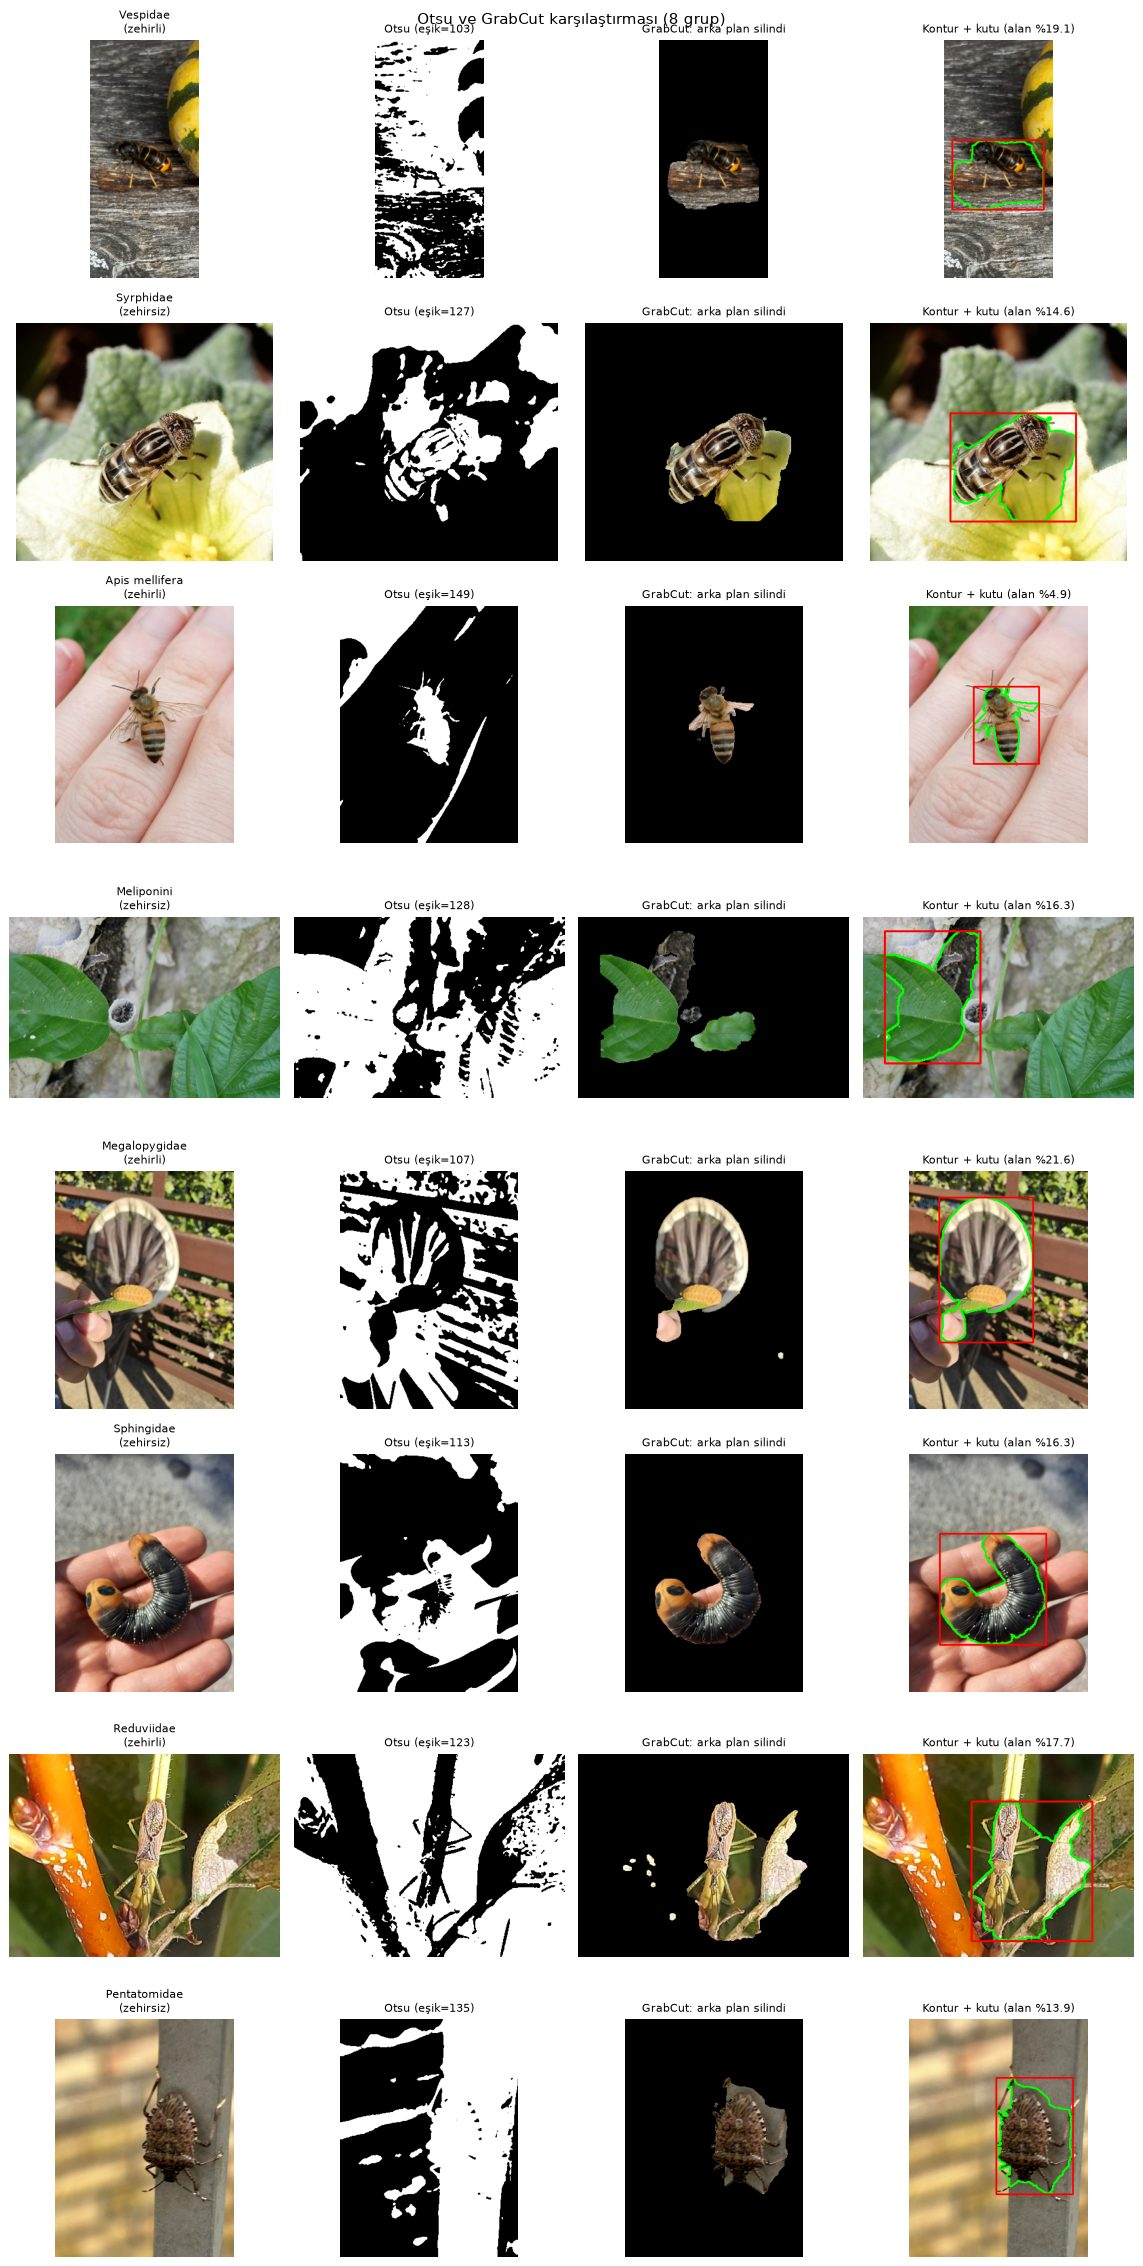

In [20]:
def grabcut(rgb, kenar=0.08, tur=5):
    h, w = rgb.shape[:2]
    m = np.zeros((h, w), np.uint8)
    dikdortgen = (int(w * kenar), int(h * kenar), int(w * (1 - 2 * kenar)), int(h * (1 - 2 * kenar)))
    cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), m, dikdortgen, np.zeros((1, 65)), np.zeros((1, 65)),
                tur, cv2.GC_INIT_WITH_RECT)
    on_plan = np.where((m == cv2.GC_FGD) | (m == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    return cv2.morphologyEx(on_plan, cv2.MORPH_OPEN, ye)

def kontur_ciz(rgb, maske):
    cizim = rgb.copy()
    konturlar, _ = cv2.findContours(maske, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if konturlar:
        k = max(konturlar, key=cv2.contourArea)
        cv2.drawContours(cizim, [k], -1, (0, 255, 0), 2)
        x, y, w, h = cv2.boundingRect(k)
        cv2.rectangle(cizim, (x, y), (x + w, y + h), (255, 0, 0), 2)
        return cizim, cv2.contourArea(k) / maske.size
    return cizim, 0.0

resimler, basliklar = [], []
for r, e in zip(ornekler.resim, ETIKET):
    g = cv2.cvtColor(r, cv2.COLOR_RGB2GRAY)
    esik, otsu = cv2.threshold(cv2.GaussianBlur(g, (5, 5), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    gc = grabcut(r)
    cizim, alan = kontur_ciz(r, gc)
    resimler += [r, otsu, cv2.bitwise_and(r, r, mask=gc), cizim]
    basliklar += [e, f"Otsu (eşik={esik:.0f})", "GrabCut: arka plan silindi", f"Kontur + kutu (alan %{100 * alan:.1f})"]
goster(resimler, basliklar, sutun=4, boyut=3.2, baslik="Otsu ve GrabCut karşılaştırması (8 grup)")

## 16. Sayısal analiz: uyarı renkleri zehirliliği ayırmaya yeter mi?

200 fotoğrafın her birinde böcek GrabCut ile ayrılır ve **yalnızca böceğin üzerinde** ölçüm yapılır:
- sarı/turuncu, kırmızı ve siyah piksel oranı
- **kenar yoğunluğu:** Canny kenar piksellerinin oranı (kıl, desen, doku ölçüsü)

Ardından yalnızca uyarı rengi oranına bakan basit bir kural (`oran > eşik → zehirli`) denenir.

In [21]:
olcum = []
t0 = time.time()
for r in gi_df.itertuples():
    m = grabcut(r.resim)
    alan = max(int((m > 0).sum()), 1)
    _, s, k, sy = renk_maskeleri(r.resim)
    c = canny(cv2.cvtColor(r.resim, cv2.COLOR_RGB2GRAY))
    olcum.append(dict(grup=r.grup, sinif=r.sinif,
                      sari=((s > 0) & (m > 0)).sum() / alan, kirmizi=((k > 0) & (m > 0)).sum() / alan,
                      siyah=((sy > 0) & (m > 0)).sum() / alan, kenar_yogunlugu=((c > 0) & (m > 0)).sum() / alan))
olcum = pd.DataFrame(olcum)
olcum["uyari_rengi"] = olcum.sari + olcum.kirmizi
print(f"{len(olcum)} fotoğraf işlendi ({time.time() - t0:.0f} sn)")

ozet = olcum.groupby(["grup", "sinif"], sort=False)[["sari", "kirmizi", "siyah", "uyari_rengi", "kenar_yogunlugu"]].mean()
(ozet * 100).round(1).rename(columns=lambda c: c + " (%)")

200 fotoğraf işlendi (228 sn)


,,sari (%),kirmizi (%),siyah (%),uyari_rengi (%),kenar_yogunlugu (%)
grup,sinif,,,,,
Vespidae,zehirli,19.2,3.8,13.0,23.0,14.1
Syrphidae,zehirsiz,48.1,0.7,11.7,48.7,13.0
Apis mellifera,zehirli,44.9,6.1,5.0,51.0,10.7
Meliponini,zehirsiz,27.5,11.9,16.4,39.4,10.5
Megalopygidae,zehirli,15.3,0.1,7.8,15.4,7.5
Sphingidae,zehirsiz,16.5,3.9,15.4,20.4,11.5
Reduviidae,zehirli,13.7,4.6,18.8,18.3,10.7
Pentatomidae,zehirsiz,16.2,4.4,15.3,20.6,11.9


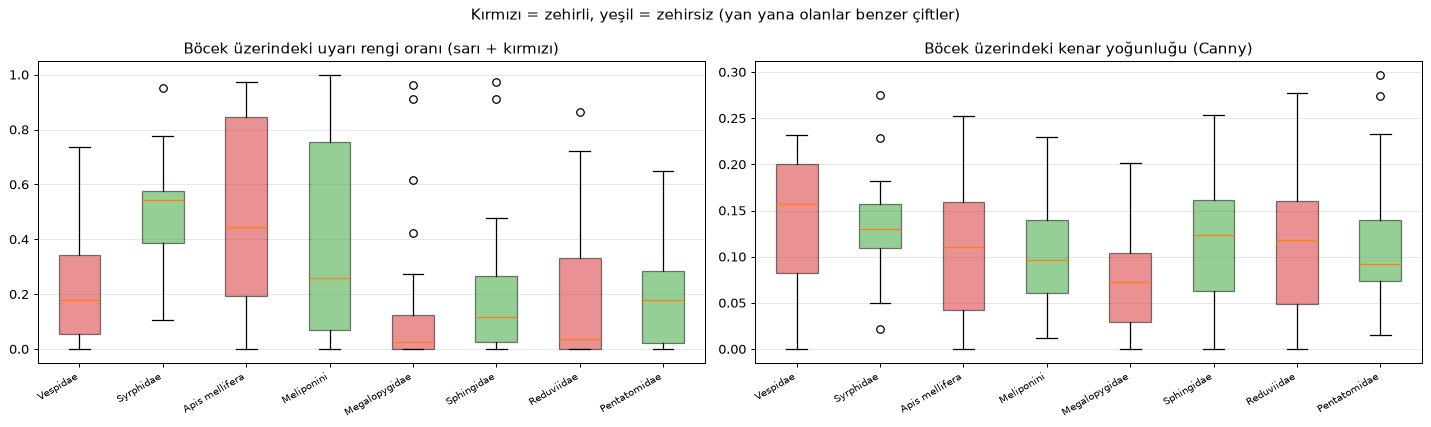

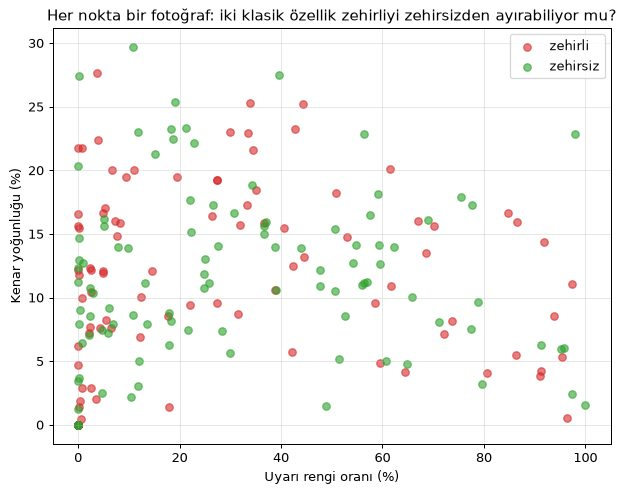

In [22]:
sira = [g for g, _, _ in CIFT_GRUPLAR]
renkler = ["#d62728" if s == "zehirli" else "#2ca02c" for _, s, _ in CIFT_GRUPLAR]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, kol, baslik in [(axes[0], "uyari_rengi", "Böcek üzerindeki uyarı rengi oranı (sarı + kırmızı)"),
                        (axes[1], "kenar_yogunlugu", "Böcek üzerindeki kenar yoğunluğu (Canny)")]:
    kutu = ax.boxplot([olcum[olcum.grup == g][kol] for g in sira], patch_artist=True)
    for p, c in zip(kutu["boxes"], renkler):
        p.set_facecolor(c); p.set_alpha(0.5)
    ax.set_xticks(range(1, len(sira) + 1)); ax.set_xticklabels(sira, rotation=30, ha="right", fontsize=8)
    ax.set_title(baslik); ax.grid(alpha=0.3, axis="y")
plt.suptitle("Kırmızı = zehirli, yeşil = zehirsiz (yan yana olanlar benzer çiftler)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
for s, c in [("zehirli", "#d62728"), ("zehirsiz", "#2ca02c")]:
    d = olcum[olcum.sinif == s]
    plt.scatter(d.uyari_rengi * 100, d.kenar_yogunlugu * 100, c=c, alpha=0.6, label=s)
plt.xlabel("Uyarı rengi oranı (%)"); plt.ylabel("Kenar yoğunluğu (%)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Her nokta bir fotoğraf: iki klasik özellik zehirliyi zehirsizden ayırabiliyor mu?")
plt.show()

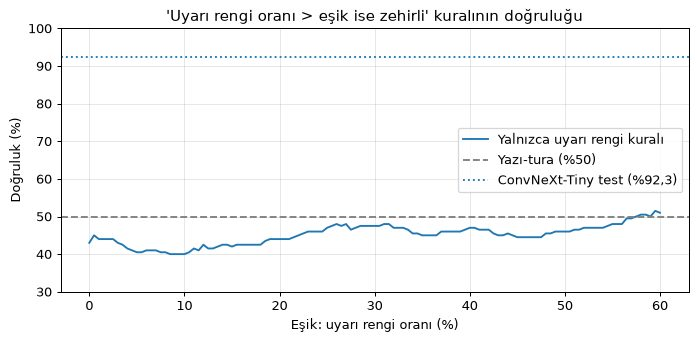

Yalnızca uyarı rengi kuralı, mümkün olan EN İYİ eşikte bile ('oran > 0.595 ise zehirli'): doğruluk %51.5
Sarı oranı: Syrphidae (zehirsiz) %48.1, Vespidae (zehirli) %19.2


,cift,zehirli_uyari_orani,zehirsiz_uyari_orani,kural_dogrulugu
0,Vespidae / Syrphidae,0.230,0.487,0.46
1,Apis mellifera / Meliponini,0.510,0.394,0.54
2,Megalopygidae / Sphingidae,0.154,0.204,0.52
3,Reduviidae / Pentatomidae,0.183,0.206,0.54


In [23]:
y = (olcum.sinif == "zehirli").astype(int).values
esikler = np.linspace(0, 0.6, 121)
dogruluk = [accuracy_score(y, olcum.uyari_rengi.values > e) for e in esikler]
en_iyi = esikler[int(np.argmax(dogruluk))]

plt.figure(figsize=(9, 3.8))
plt.plot(esikler * 100, np.array(dogruluk) * 100, label="Yalnızca uyarı rengi kuralı")
plt.axhline(50, color="gray", ls="--", label="Yazı-tura (%50)")
plt.axhline(92.3, color="#1f77b4", ls=":", label="ConvNeXt-Tiny test (%92,3)")
plt.xlabel("Eşik: uyarı rengi oranı (%)"); plt.ylabel("Doğruluk (%)"); plt.ylim(30, 100); plt.legend(); plt.grid(alpha=0.3)
plt.title("'Uyarı rengi oranı > eşik ise zehirli' kuralının doğruluğu"); plt.show()

print(f"Yalnızca uyarı rengi kuralı, mümkün olan EN İYİ eşikte bile ('oran > {en_iyi:.3f} ise zehirli'): "
      f"doğruluk %{100 * max(dogruluk):.1f}")
print(f"Sarı oranı: Syrphidae (zehirsiz) %{100 * olcum[olcum.grup == 'Syrphidae'].sari.mean():.1f}, "
      f"Vespidae (zehirli) %{100 * olcum[olcum.grup == 'Vespidae'].sari.mean():.1f}")

cift_sonuc = []
for i in range(0, len(CIFT_GRUPLAR), 2):
    z, zs = CIFT_GRUPLAR[i][0], CIFT_GRUPLAR[i + 1][0]
    d = olcum[olcum.grup.isin([z, zs])]
    cift_sonuc.append(dict(cift=f"{z} / {zs}",
                           zehirli_uyari_orani=d[d.grup == z].uyari_rengi.mean(),
                           zehirsiz_uyari_orani=d[d.grup == zs].uyari_rengi.mean(),
                           kural_dogrulugu=accuracy_score(d.sinif == "zehirli", d.uyari_rengi > en_iyi)))
pd.DataFrame(cift_sonuc).round(3)

## Görüntü işleme bölümünün sonucu

- **Ön işleme:** Histogram eşitleme / CLAHE karanlık fotoğrafın kontrastını geri kazandırır. Gürültü türüne göre doğru filtre değişir: Gauss gürültüsünde kenarı koruyan **bilateral**, tuz-biber gürültüsünde **medyan** filtre PSNR'ı en çok artırır; bilateral filtre tuz-biber gürültüsünde işe yaramaz.
- **Evrişim ve kenar bulma:** Aynı fotoğraf, yalnızca 3×3 çekirdeğin sayıları değiştirilerek bulanıklaşır, keskinleşir ya da kenarlarına ayrılır. Elle yazılan Sobel çekirdeği `cv2.Sobel` ile birebir aynı sonucu verir. CNN'ler bu çekirdeklerin sayılarını kendileri öğrenir.
- **Segmentasyon:** Otsu eşikleme karmaşık arka planda başarısızdır; GrabCut böceği çoğu fotoğrafta ayırır, fakat böcek çok küçükse ya da arka plan dikkat çekiciyse yanılabilir.
- **Renk analizi:** HSV maskesi uyarı renklerini yakalar, ama **renk tek başına yetmez**: arı taklitçisi Syrphidae'de sarı oranı eşek arısından bile yüksektir ve yalnızca renge bakan bir kural yazı-tura düzeyinde kalır.

Bu nedenle projede kenar, doku, şekil ve rengi birlikte ve otomatik olarak öğrenen **evrişimli sinir ağları** kullanılmıştır (ConvNeXt-Tiny, %92,3 test doğruluğu).